# PHYB57 · Tutorial 4「算法复杂度与 Big-O」逐行人话版

> 算法复杂度 → Big-O 记号 → O(1) / O(log n) / O(n) / O(n log n) / O(n²) → 实测验证
> 对应文件：`tut-4.html`（Jupyter 导出的 Tutorial 4，共 15 个单元格）

这份 notebook 干三件事：

1. **原样保留** Tutorial 4 的每一个 markdown 格和每一个代码格 —— 课件代码**一字未改**，可以直接跑；
2. **逐行讲解每一段代码** —— 用「行号 + 代码 + 人话」的表格，对着看就行；
3. **补上课件缺的实验** —— 课件说「O(n log n) 比 O(n²) 快」，我们就真的去计时、数操作、画双对数图、拟合斜率，把这句话**量**出来。

## 怎么读

| 标记 | 含义 |
|---|---|
| **课件原文** | 原 Tutorial 4 的英文，一字未改 |
| **人话版** | 把那段英文翻译成人话 |
| **📖 这一格在做什么** | 逐行翻译代码，左列是行号，对着看 |
| ⚠️ | **容易踩的坑** |
| 🧪 | **补充实验** —— 课件里没有，但能让你亲眼看到复杂度 |
| 📌 | **勘误** —— 原文有明显笔误的地方 |
| 🔍 CHECK | 课件风格的自问自答，答案紧跟其后 |

## 目录

| 小节 | 主题 | 课件代码格 | 补充实验 |
|---|---|---|---|
| §0 | 开跑之前：环境检查 | — | 版本 / 字体自检 |
| §1 | 什么是算法复杂度 | — | 秒表有多不靠谱 / 换成数操作次数 |
| §2 | Big-O 记号与六种增长阶 | — | 数值对照表 + 增长曲线图 |
| §3 | 常数时间 $\mathcal{O}(1)$ | ✅ 第 1 格 | 不同 n 下取下标 / 查字典耗时 |
| §4 | 线性时间 $\mathcal{O}(n)$ | ✅ 第 2 格 | 时间是否真的与 n 成正比 |
| §5 | 二次时间 $\mathcal{O}(n^2)$ | ✅ 第 3 格 | 验证 n(n−1)/2 + 计时 |
| §6 | 对数时间 $\mathcal{O}(\log n)$ | ✅ 第 4 格 | 二分步数 + 二分法求根 |
| §7 | 线性对数时间 $\mathcal{O}(n\log n)$ | ✅ 第 5 格 | 数搬运次数 + 对比内置 sorted |
| §8 | 实测运行时间对比 | ✅ 第 6 格 | 双对数图 + 从数据拟合出阶数 |
| §9 | 一张表收尾 | — | 三个坑 + 三个好习惯 |
| §10 | 自测 6 题 | — | — |
| §11 | 自测题答案与验证代码 | — | — |

## 开跑之前先记住这一句

> **复杂度不是「跑多快」，而是「n 变大时，工作量按什么形状涨」。**
>
> 秒表量到的是「这台电脑此刻的快慢」；Big-O 量到的是**曲线的形状**。

---

---
# §0 · 开跑之前

Tutorial 4 的**全部课件代码只用到标准库**（`time`），一个包都不装就能跑完。
只有画图那三格需要 `matplotlib`；没装的话那三格会**自动跳过并打印一句提示**，其余内容完全不受影响。

```bash
pip install matplotlib   # 可选，只为看图
```

- `time` —— 计时（§1、§4、§5、§7、§8）
- `math` —— `log2`，用来算理论操作数
- `matplotlib` —— 画图（可选）

先跑下面这一格，确认环境和中文字体没问题。

In [1]:
# §0 —— 本章要用到的全部工具，一次性导入
import time        # 计时（§1、§4、§5、§7、§8 全用它）
import sys         # 查 Python 版本
import math        # log2：算「理论上要多少步」时用

print("Python", sys.version.split()[0])

# matplotlib 是可选依赖：装了就能画图，没装也照样跑完全章
try:
    import matplotlib
    import matplotlib.pyplot as plt
    HAS_MPL = True
except ImportError:
    HAS_MPL = False

if HAS_MPL:
    from matplotlib import font_manager, rcParams

    def setup_cjk_font():
        """让 matplotlib 能显示中文。
        matplotlib 3.6+ 支持「字体回退」：给一串字体名，前一个缺哪个字就自动用后一个补。
        不设的话，图上所有中文都会变成一个个方框（俗称豆腐块）。
        注意：必须设 font.family，只设 font.sans-serif 时 matplotlib 并不会逐字回退。"""
        found = []
        for name in ["PingFang HK", "Heiti TC", "Songti SC", "Arial Unicode MS",
                     "Hiragino Sans GB", "SimHei", "Microsoft YaHei", "Noto Sans CJK SC"]:
            try:
                font_manager.findfont(name, fallback_to_default=False)
            except Exception:
                continue                      # 这个字体没装，试下一个
            found.append(name)
        if found:
            rcParams["font.family"] = found          # 整串字体都给 matplotlib，缺字自动回退
            rcParams["axes.unicode_minus"] = False   # 让负号能正常显示
        return found

    rcParams["figure.dpi"] = 120
    _fonts = setup_cjk_font()
    print("中文字体:", "、".join(_fonts) if _fonts else "(没找到，图上中文会显示成方框)")
    print("matplotlib", matplotlib.__version__, "就绪 → 三格画图会正常工作")
else:
    print("没装 matplotlib → 三格画图会自动跳过（其余内容完全不受影响）")

print()
info = time.get_clock_info("perf_counter")
print(f"time.perf_counter 分辨率 ≈ {info.resolution:.2e} 秒"
      f"（{info.resolution * 1e9:.0f} 纳秒），单调={info.monotonic}")

Python 3.13.9


中文字体: PingFang HK、Heiti TC、Songti SC、Arial Unicode MS、Hiragino Sans GB
matplotlib 3.10.6 就绪 → 三格画图会正常工作

time.perf_counter 分辨率 ≈ 4.17e-08 秒（42 纳秒），单调=True


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2-4 | `import time / sys / math` | 三个都是**标准库**，开箱即用。`time` 用来掐表，`sys` 用来打印 Python 版本，`math` 用来算 $\log_2$ |
| 6 | `print("Python", ...)` | 打印版本号。**为什么要在意版本？** 不同 Python 版本的常数因子能差好几倍（§8 会看到），所以记录环境是好习惯 |
| 9-14 | `try: import matplotlib ...` | 「先试着导入，失败就记一个 `HAS_MPL = False`」。**这是处理可选依赖的标准写法** —— 后面每一格画图都先问一句 `if HAS_MPL:` |
| 19-34 | `def setup_cjk_font():` | matplotlib 默认字体里**没有汉字**，中文会画成方框。这个函数挨个试系统里常见的中文字体名，把**装了的全部收集起来** |
| 23-30 | `font_manager.findfont(name, fallback_to_default=False)` | 查这个字体在不在。`fallback_to_default=False` 是关键 —— 不加的话，找不到时它会**默默返回默认字体**（于是你根本不知道字体没生效） |
| 31-33 | `rcParams["font.family"] = found` | **把一整串字体名都交给 matplotlib**。matplotlib 3.6+ 支持「字体回退」：某个字体缺哪个字，就自动去列表里下一个字体拿（比如 macOS 的 PingFang HK 恰好缺一个「杂」字，就会自动从 Heiti TC 取）。⚠️ **必须设 `font.family`**——只设 `font.sans-serif` 时 matplotlib 不会逐字回退，会直接画方框并甩你一条 UserWarning（这个坑我实测过） |
| 33 | `rcParams["axes.unicode_minus"] = False` | 中文字体里的「−」和 ASCII 减号不是一个字符，不关掉的话负号会变方框 |
| 44-46 | `time.get_clock_info("perf_counter")` | 打印计时器的**分辨率**和是否**单调** |

> ⚠️ **为什么强调「单调」（monotonic）？**
> `time.time()` 读的是墙上时钟，系统对时（NTP）时可能**往回跳**，一减就得到负数。
> `time.perf_counter()` 保证只增不减，而且是精度最高的那个 —— **计时永远用它**。

> 💡 这一章**全程不写文件、不读文件**，不会在你的目录里留下任何垃圾。

---

---
# §1 · 什么是算法复杂度（What is Algorithmic Complexity?）

## 课件原文

> **WHAT IS ALGORITHMIC COMPLEXITY?**
>
> Measuring how "fast" a program runs by using a stopwatch in seconds isn't really useful; instead, in computer science we measure algorithmic complexity by analyzing how the number of basic operations grows as a function of the input size (n).
>
> - **input size (n)**: the amount of data being processed (e.g., length of a list, number of particles, number of data points)
> - **basic operations**: operations that take roughly constant time regardless of input size (e.g., addition, assignment, comparison)
> - **time complexity**: how the execution time grows as n goes to infinity

## 人话版

**为什么不能用秒表？**

假设你写了两段代码 A 和 B，在你的笔记本上 A 跑 0.8 秒、B 跑 1.2 秒。你能说「A 的算法比 B 好吗」？不能，因为秒表量到的是这么一堆东西的总和：

- 你的**电脑快慢**（换个 CPU 结论就变）
- **Python 版本 / 是不是用了 C 扩展**（§7 会看到同一个算法能差 50 倍）
- **后台在跑什么**（微信、Spotlight 索引、风扇转速）
- **数据长什么样**（最好情况还是最坏情况）

而且它**不能外推**：现在 B 慢，n 再涨 10 倍时完全可能 B 快得多。

所以计算机科学换了一把尺子：**数操作次数**。

| 概念 | 原文 | 人话 | 例子 |
|---|---|---|---|
| **input size (n)** | 输入规模 | 要处理的数据量 | 列表长度、粒子个数、数据点个数 |
| **basic operation** | 基本操作 | 耗时不随 n 变的一次小动作 | 加法、赋值、比较 |
| **time complexity** | 时间复杂度 | 当 n → ∞ 时，操作次数**按什么形状涨** | 一次循环 → 大约 n 次操作 |

**关键在最后一行**：我们关心的不是「n = 10 时要跑几步」，而是「**n 翻倍时，步数怎么变**」。

> 💡 一句话：**复杂度是一把「跟机器无关」的尺子。它量的是曲线的形状，不是曲线的高度。**

## 📌 勘误

课件原文第一条写的是：

> input size (n): **6he** amount of data being processed

`6he` 是 `the` 的笔误。后面所有内容不受影响，这里只标注一下。

## 🧪 补充实验：两把尺子当面比一比

下面两格，先亲身体验「秒表有多不靠谱」，再体验「数操作次数有多靠谱」。

In [2]:
# 🧪 实验 1.1 —— 秒表有多不靠谱？
# 同一段代码、同一个输入，连跑 5 次，看看读数差多少

def work(n):
    """一段故意写得很笨的求和：老老实实做 n 次加法。"""
    total = 0
    for i in range(n):
        total += i
    return total

N = 200_000
print(f"同一段代码、同一输入 n = {N:,}，连跑 5 次：")

times = []
for trial in range(5):
    t0 = time.perf_counter()      # 掐表开始
    work(N)
    dt = time.perf_counter() - t0 # 掐表结束，相减得耗时
    times.append(dt)
    print(f"  第 {trial + 1} 次: {dt * 1000:7.3f} ms")

print(f"\n最快 {min(times) * 1000:.3f} ms，最慢 {max(times) * 1000:.3f} ms，"
      f"相差 {(max(times) / min(times) - 1) * 100:.1f}%")

同一段代码、同一输入 n = 200,000，连跑 5 次：
  第 1 次:   4.308 ms
  第 2 次:   4.269 ms
  第 3 次:   4.376 ms
  第 4 次:   4.307 ms
  第 5 次:   4.337 ms

最快 4.269 ms，最慢 4.376 ms，相差 2.5%


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 4-9 | `def work(n):` | 一段**故意写得很笨**的求和。之所以不用内置 `sum()`，是因为内置函数是 C 写的、快到看不见抖动 |
| 8 | `total += i` | 一次加法 + 一次赋值 ≈ 两次基本操作。循环 n 次 ⇒ 大约 2n 次基本操作 |
| 11 | `N = 200_000` | **固定输入规模**，只让「机器状态」变 —— 这样剩下的差异就只可能来自环境 |
| 13 | `times = []` | 空列表，用来收集 5 次读数 |
| 14-18 | `for trial in range(5):` | 同一件事做 5 遍 |
| 15-17 | `t0 = ...  dt = ... - t0` | 掐表的标准写法：开始前取一次时间戳，结束后取一次，**相减** |
| 16 | `time.perf_counter()` | 分辨率最高、单调递增的计时器（§0 打印过它的参数） |
| 20-21 | `min / max / 相差%` | 把 5 次结果摆一起看离散程度 |

> ⚠️ **你会看到的现象**：5 次读数**不可能完全一样**，通常第 1 次最慢。原因：
> - **第 1 次慢** —— 函数刚被调用，CPU 指令缓存 / 分支预测还没「热」起来；
> - **后面还在抖** —— 操作系统在后台切换进程、CPU 降频省电、内存页换入换出……
>
> 这正是课件第一句话的意思：**秒表测的不是算法，是算法 + 整台电脑的当下状态。**

> 📌 **顺手记一条工程习惯**：写代码计时，永远不要只测一次 —— 至少取 `min()`。**最快的那一次最接近「纯算法」的耗时**，因为它受干扰最少。

In [3]:
# 🧪 实验 1.2 —— 换一把尺子：数「基本操作」的次数
# 做同一件事（循环 n 次），但这次只关心「做了多少次基本操作」

def count_operations(n):
    """返回基本操作被执行的总次数。"""
    ops = 0
    for _ in range(n):     # 循环体执行 n 次
        ops += 1           # 这一次加法 = 一次基本操作
    return ops

print(f"{'n':>10} | {'操作次数':>10} | {'操作次数 / n':>14}")
print("-" * 44)
for n in [10, 100, 1_000, 10_000]:
    ops = count_operations(n)
    print(f"{n:>10,} | {ops:>10,} | {ops / n:>14.1f}")

         n |       操作次数 |       操作次数 / n
--------------------------------------------
        10 |         10 |            1.0
       100 |        100 |            1.0
     1,000 |      1,000 |            1.0
    10,000 |     10,000 |            1.0


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 4-9 | `def count_operations(n):` | 手动记一个计数器 `ops`，每做一次基本操作就 +1。（真实工程里当然不会这么写代码，这只是为了**把复杂度画出来看**） |
| 7 | `for _ in range(n):` | `_` 表示「这个循环变量我不关心」。循环跑 n 次 |
| 8 | `ops += 1` | 每轮记 1 次 |
| 11-15 | `print(...)` | 打印 n、操作次数、以及**比值** |

> 💡 **盯着最后一列看**：不管 n 是 10 还是 10,000，`操作次数 / n` 永远等于 **1**。
>
> 这个「**比值恒定**」就是线性复杂度的指纹：$f(n) = n$。

> 🔍 **CHECK 1**：如果把循环体改成 `ops += 2`，最后一列会变成几？复杂度还是 $\mathcal{O}(n)$ 吗？
>
> **答**：变成 **2**。比值是个**常数** ⇒ 依然是 $\mathcal{O}(n)$。这就是 Big-O 里「**常数因子不重要**」的直观含义（§2 会给形式定义）。
>
> 🔍 **CHECK 2**：那 `ops += n` 呢？
>
> **答**：比值变成 n ⇒ 操作次数是 $n^2$ ⇒ 那是 $\mathcal{O}(n^2)$。**看比值随 n 怎么变，就能读出阶数** —— 这是整章的方法论。

---

---
# §2 · Big-O 记号（Big-O Notation）

## 课件原文

> **BIG-O NOTATION**
>
> Big-O notation ($\mathcal{O}$) describes the upper bound (worst-case scenario) of an algorithm's growth rate as the input size n becomes arbitrarily large.
>
> ### Common Orders of Growth (from fastest to slowest):
>
> - $\mathcal{O}(1)$: constant time — runtime does not depend on input size
> - $\mathcal{O}(\log n)$: logarithmic time — problem size is divided by a factor at each step
> - $\mathcal{O}(n)$: linear time — runtime scales proportionally with n
> - $\mathcal{O}(n \log n)$: linearithmic time — standard for efficient sorting (e.g. Merge Sort, Timsort in Python)
> - $\mathcal{O}(n^2)$: quadratic time — typical of nested loops over the data
> - $\mathcal{O}(2^n)$: exponential time — operations double with each added element

## 人话版

把第一句拆成三个关键词：

| 关键词 | 原文 | 人话 |
|---|---|---|
| **upper bound** | 上界 | 「**最多**要多少步」。真实步数可能更少，但**不会超过**这条线 |
| **worst-case** | 最坏情况 | 把输入摆成最坑的那一种，仍然能保证的界 |
| **arbitrarily large** | n 任意大 | 只在 **n → ∞** 的极限意义下成立。n 很小时，常数因子反而可能占主导 |

**形式定义**（课件没写，但看懂了以后看论文/教材不慌）：

$$
f(n) = \mathcal{O}\big(g(n)\big)
\quad\Longleftrightarrow\quad
\exists\, C > 0,\ \exists\, n_0,\ \forall\, n \ge n_0:\quad f(n) \le C \cdot g(n)
$$

翻成人话：**「从某个 $n_0$ 往后，$f$ 一直被 $C$ 倍的 $g$ 压在下面。」**

- $C$ 是任意常数 ⇒ 所以 $\mathcal{O}(3n) = \mathcal{O}(n)$：**系数被丢掉**；
- $n_0$ 是「从哪儿开始算」 ⇒ 所以 $\mathcal{O}(n + 100) = \mathcal{O}(n)$：**低阶项被丢掉**。

> ⚠️ **最容易搞错的一点**：Big-O 是**上界**，不是「等于」。
> 严格讲，一个 $\mathcal{O}(n)$ 的算法**也**是 $\mathcal{O}(n^2)$ 的（因为 $n \le n^2$ 对 $n \ge 1$ 成立）。
> 但平时我们说「这个算法是 $\mathcal{O}(n)$」，意思永远是「**最紧的那个界**」。

## 六种增长阶，一眼看懂

| 记号 | 中文 | 一句话 | 典型场合 |
|---|---|---|---|
| $\mathcal{O}(1)$ | 常数 | n 再大也不变 | 按下标取值、哈希表查询 |
| $\mathcal{O}(\log n)$ | 对数 | 每步砍一半 | 二分查找、二分法求根 |
| $\mathcal{O}(n)$ | 线性 | 和 n 成正比 | 单层循环、`sum()`、线性查找 |
| $\mathcal{O}(n\log n)$ | 线性对数 | 砍 $\log n$ 层，每层扫 n 个 | 归并排序、Timsort（Python 的 `sorted`） |
| $\mathcal{O}(n^2)$ | 二次 | 两层嵌套循环 | N 体问题、朴素矩阵乘法 |
| $\mathcal{O}(2^n)$ | 指数 | 每加一个元素翻倍 | 穷举所有子集 |

> 🎯 **记忆抓手**：所有「**分而治之**」的算法，复杂度几乎都是 $\mathcal{O}(n\log n)$ ——
> 因为「**分**」贡献了 $\log n$ 层，「**治**」贡献了每层 n 的工作量。§7 会亲手验证。

## 🧪 补充实验：把六个阶摆在一张表里

先看**纸上的数值**，等会儿再拿秒表去测（§8）。

In [4]:
# 🧪 实验 2.1 —— 六种增长阶的数值对照表
# 2^n 涨得太快，浮点数装不下（会变成 inf），所以用「10 的多少次方」来表示

def pow2_str(n):
    """把 2^n 显示成 10^x 的形式，避免浮点溢出。"""
    if n <= 1023:
        return f"{2 ** n:.3g}"
    return f"10^{n * math.log10(2):.0f}"     # 2^n = 10^(n*log10(2))

def build_row(n):
    return (f"{n:>12,} | {1:>8} | {math.log2(n):>10.2f} | {n:>12,} | "
            f"{n * math.log2(n):>14.3g} | {n ** 2:>14.3g} | {pow2_str(n):>14}")

header = (f"{'n':>12} | {'O(1)':>8} | {'O(log n)':>10} | {'O(n)':>12} | "
          f"{'O(n log n)':>14} | {'O(n^2)':>14} | {'O(2^n)':>14}")
print("六种增长阶，在同一个 n 下各需要多少次基本操作：")
print(header)
print("-" * len(header))
for n in [10, 100, 1_000, 1_000_000]:
    print(build_row(n))

六种增长阶，在同一个 n 下各需要多少次基本操作：
           n |     O(1) |   O(log n) |         O(n) |     O(n log n) |         O(n^2) |         O(2^n)
------------------------------------------------------------------------------------------------------
          10 |        1 |       3.32 |           10 |           33.2 |            100 |       1.02e+03
         100 |        1 |       6.64 |          100 |            664 |          1e+04 |       1.27e+30
       1,000 |        1 |       9.97 |        1,000 |       9.97e+03 |          1e+06 |      1.07e+301
   1,000,000 |        1 |      19.93 |    1,000,000 |       1.99e+07 |          1e+12 |      10^301030


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 4-8 | `def pow2_str(n):` | $2^n$ 在 n = 1024 时就超出双精度浮点的上限了（直接变 `inf`），所以自己写个函数把它表示成「10 的多少次方」 |
| 6-7 | `if n <= 1023: ...` | 小的时候直接算；大了就取常用对数：$2^n = 10^{\,n\log_{10}2}$ |
| 10-13 | `def build_row(n):` | 拼出一行表格字符串。`>12` 表示「右对齐、占 12 个字符宽」，纯粹为了对齐好看 |
| 11 | `math.log2(n)` | Python 的以 2 为底对数。**计算机科学里 $\log$ 默认就是 $\log_2$** |
| 16-19 | `print(header) / print("-" * len(header))` | 打印表头和一条分割线，`len(header)` 让分割线自动和表头一样长 |

**(运行上面的格子，然后回来对照这张表)**

> 🔍 **盯着输出看三件事**（这是整章最重要的一张表）：
>
> 1. **n 从 10 涨到 10⁶（涨 10 万倍）**：$\mathcal{O}(\log n)$ 只从 **3.32 涨到 19.93** —— 只涨了 **6 倍**。
> 2. $\mathcal{O}(n^2)$ 在 n = 10⁶ 时要 **10¹² 次操作**。你的电脑一秒大概能做 10⁸~10⁹ 次基本操作 ⇒ 这一趟要跑 **十几分钟到几小时**。
> 3. $\mathcal{O}(2^n)$ 在 n = 10⁶ 时是 $10^{301030}$ —— **比可观测宇宙的原子总数（约 $10^{80}$）还大得多**。
>
> 所以课件最后说「$\mathcal{O}(n\log n)$ 对大输入比 $\mathcal{O}(n^2)$ 快」，不是快一点点，是**快 100 亿倍量级**。

> ⚠️ **注意 n 很小时的反直觉现象**：n = 10 时，$\mathcal{O}(n\log n)$ 的 33 次**大于** $\mathcal{O}(n)$ 的 10 次 —— 阶数高的反而步数多，这很正常。
> 更实际的情况是：一个「常数极大」的 $\mathcal{O}(n)$ 算法，在 n = 10 时完全可能跑不过一个「常数极小」的 $\mathcal{O}(n^2)$ 算法。
> **Big-O 只在 n 足够大时说话** —— 这正是定义里那个 $n_0$ 的作用。

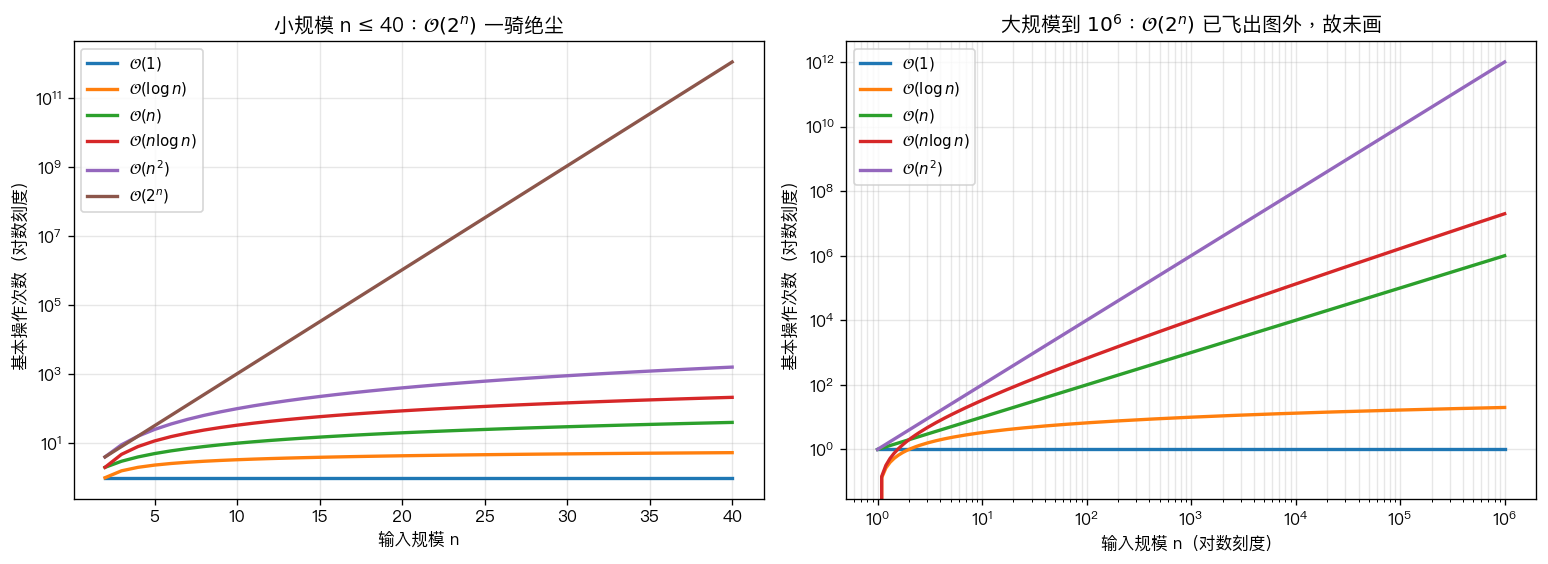

In [5]:
# 🧪 实验 2.2 —— 把六条曲线画出来
# （没装 matplotlib 就自动跳过这一格，数据在上面的表里已经有了）

if not HAS_MPL:
    print("没装 matplotlib，跳过画图（数值表在上面的输出里）")
else:
    n_small = list(range(2, 41))          # 小规模：2 ~ 40（从 2 起，因为 log2(1)=0 在对数轴上画不出来）
    n_big = [10 ** (i / 25) for i in range(0, 151)]   # 大规模：1 ~ 10^6，151 个点

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13, 4.8))

    # ---------- 左图：小 n，六条曲线全画上 ----------
    ax1.plot(n_small, [1] * len(n_small), lw=2, label=r"$\mathcal{O}(1)$")
    ax1.plot(n_small, [math.log2(n) for n in n_small], lw=2, label=r"$\mathcal{O}(\log n)$")
    ax1.plot(n_small, n_small, lw=2, label=r"$\mathcal{O}(n)$")
    ax1.plot(n_small, [n * math.log2(n) for n in n_small], lw=2, label=r"$\mathcal{O}(n\log n)$")
    ax1.plot(n_small, [n ** 2 for n in n_small], lw=2, label=r"$\mathcal{O}(n^2)$")
    ax1.plot(n_small, [2 ** n for n in n_small], lw=2, label=r"$\mathcal{O}(2^n)$")
    ax1.set_yscale("log")
    ax1.set_xlabel("输入规模 n")
    ax1.set_ylabel("基本操作次数（对数刻度）")
    ax1.set_title("小规模 n ≤ 40：$\\mathcal{O}(2^n)$ 一骑绝尘")
    ax1.grid(True, which="both", alpha=0.3)
    ax1.legend(fontsize=9)

    # ---------- 右图：大规模，双对数坐标 ----------
    ax2.plot(n_big, [1] * len(n_big), lw=2, label=r"$\mathcal{O}(1)$")
    ax2.plot(n_big, [math.log2(n) for n in n_big], lw=2, label=r"$\mathcal{O}(\log n)$")
    ax2.plot(n_big, n_big, lw=2, label=r"$\mathcal{O}(n)$")
    ax2.plot(n_big, [n * math.log2(n) for n in n_big], lw=2, label=r"$\mathcal{O}(n\log n)$")
    ax2.plot(n_big, [n ** 2 for n in n_big], lw=2, label=r"$\mathcal{O}(n^2)$")
    ax2.set_xscale("log")
    ax2.set_yscale("log")
    ax2.set_xlabel("输入规模 n（对数刻度）")
    ax2.set_ylabel("基本操作次数（对数刻度）")
    ax2.set_title("大规模到 $10^6$：$\\mathcal{O}(2^n)$ 已飞出图外，故未画")
    ax2.grid(True, which="both", alpha=0.3)
    ax2.legend(fontsize=9)

    plt.tight_layout()
    plt.show()

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 4-5 | `if not HAS_MPL:` | 没装 matplotlib 就打个招呼走人，**不让后面报错**（这是可选依赖的正确姿势） |
| 7-8 | `n_small / n_big` | 两组横坐标。`n_big` 用 `10 ** (i / 25)` 生成，即在对数轴上**等间距**取点 —— 这样双对数图上曲线才是均匀的 |
| 10 | `plt.subplots(1, 2, figsize=(13, 4.8))` | 一张图分成「1 行 2 列」两个面板，左 `ax1`、右 `ax2` |
| 13-18 | `ax1.plot(...)` | 左图：n 从 2 到 40，六条曲线一起画（从 2 起，因为 $\log_2 1 = 0$ 在对数纵轴上画不出来） |
| 19 | `ax1.set_yscale("log")` | **纵轴取对数**。不取的话 $\mathcal{O}(2^n)$ 会把其它五条全压成贴着 x 轴的一条直线，什么也看不见 |
| 22-27 | `ax2.plot(...)` | 右图：n 一直画到 10⁶。$\mathcal{O}(2^n)$ **故意不画** —— $2^{10^6} = 10^{301030}$，画上去纵轴会被拉到 10³⁰¹⁰³⁰，其余曲线全部退化成一条线 |
| 20-21 | `set_xlabel / set_ylabel` | 坐标轴名字。带 `r""` 前缀的是 **LaTeX 数学式**，matplotlib 会自动渲染得漂亮 |
| 22 | `$\\mathcal{O}(2^n)$` | 在普通字符串里写反斜杠要写两遍（`\\` 才是一个 `\`） |
| 33-34 | `plt.tight_layout(); plt.show()` | 自动调整边距防止标签被切掉；显示图像 |

> 💡 **看图的方法（本章最有用的一招）**：
>
> **在双对数坐标下，幂函数 $y = n^k$ 的图像是一条直线，斜率正好就是 $k$。**
>
> 所以右图里 $\mathcal{O}(n)$ 是斜率 1 的直线，$\mathcal{O}(n^2)$ 是斜率 2 的直线，$\mathcal{O}(n\log n)$ 则比直线**微微上翘一点点**（因为多了一个 $\log n$ 因子）。
>
> §8 我们会用这个性质，**反过来从秒表读数里量出复杂度阶数**。

---

---
# §3 · 常数时间：$\mathcal{O}(1)$

## 课件原文

> **CONSTANT TIME: $\mathcal{O}(1)$**
>
> An algorithm runs in $\mathcal{O}(1)$ time if the number of operations is fixed and independent of the input size n.

## 人话版

**操作次数是个固定的数，跟 n 一点关系都没有。**

注意「固定」的含义：不是「只要 1 次操作」，而是「不管 n 多大，**永远就那么几次**」。

| 操作 | 为什么是 $\mathcal{O}(1)$ |
|---|---|
| `data[0]` / `data[-1]` / `data[i]` | 列表在内存里是**连续**的：地址 = 起始地址 + i × 元素大小。一次乘法一次加法就定位到了 |
| `a + b` / `a * b` | CPU 一条指令，跟数字多大无关（定长浮点） |
| `scores["Alex"]` | 字典是**哈希表**：先算哈希值 → 直接跳到对应桶，不需要挨个找 |
| `len(data)` | Python 把长度**存在列表对象里**，直接读出来，不数 |

> ⚠️ **最容易混淆的一组**（考试爱考）：
>
> | 写法 | 复杂度 | 为什么 |
> |---|---|---|
> | `data[0]` | $\mathcal{O}(1)$ | 按下标直接算地址 |
> | `x in data` | $\mathcal{O}(n)$ | **要挨个比**，最坏比到最后一个 |
> | `data.index(x)` | $\mathcal{O}(n)$ | 同上，线性查找 |
> | `data.append(x)` | $\mathcal{O}(1)$**摊销** | 尾部直接放；偶尔要扩容，但**平摊下来**是常数 |
> | `data.insert(0, x)` | $\mathcal{O}(n)$ | 插在头上，后面所有元素都得**整体后移一格** |

> ⚠️ **字典「平均 $\mathcal{O}(1)$」≠「永远 $\mathcal{O}(1)$」**。
> 课件原文写的是 "dictionary key lookup takes O(1) **on average**" —— 这个 "on average" 不能丢。
> 哈希冲突极多时（比如所有键的哈希值都撞在一个桶里），最坏会退化到 $\mathcal{O}(n)$。

## 课件代码（原文，一字未改）

In [6]:
# O(1) Operations
data = [10, 20, 30, 40, 50, 60, 70, 80, 90, 100]

# accessing a list element by index takes O(1) time
first = data[0]
last = data[-1]

# basic arithmetic takes O(1) time
calc = (first + last) * 2

# dictionary key lookup takes O(1) on average
scores = {"Alex": 87, "Sam": 92, "Jordan": 78}
alex_score = scores["Alex"]

print("First element:", first)
print("Last element:", last)
print("Calculation result:", calc)
print("Dict lookup ('Alex'):", alex_score)

First element: 10
Last element: 100
Calculation result: 220
Dict lookup ('Alex'): 87


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 1 | `# O(1) Operations` | 注释：这一格演示常数时间 |
| 2 | `data = [10, 20, ..., 100]` | 建一个 10 个元素的列表。n = 10，但**下面每一步都跟 n 无关** |
| 5 | `first = data[0]` | 取第 0 个。列表连续存放，`data[0]` 的地址 = 起始地址 + 0×8 字节，**一步算出来** |
| 6 | `last = data[-1]` | 取最后一个。Python 的负下标就是 `len(data) - 1`，仍然是先算地址再取，**一步** —— 它**不是**从后往前遍历 |
| 9 | `calc = (first + last) * 2` | 一次加法 + 一次乘法。不管数字多大，CPU 都是一条指令（定长浮点数） |
| 12 | `scores = {"Alex": 87, ...}` | 建一个 3 键字典 |
| 13 | `alex_score = scores["Alex"]` | 字典查询：算 `hash("Alex")` → 直接跳到对应桶。**平均一步到位** |
| 15-18 | `print(...)` | 把四个结果打出来，验证确实拿到了值 |

> 🔍 **CHECK**：把 `data` 从 10 个元素改成 1000 万个元素，上面四行哪一行的耗时**会变**？
>
> **答**：都不会变（忽略噪声）。这正是 $\mathcal{O}(1)$ 的定义 —— 操作数**独立于** n。
> 注意第 2 行「建这个列表」**本身**是 $\mathcal{O}(n)$，但那不是这格要演示的东西。

> 🔍 **CHECK**：那 `data[5000000]`（取中间）呢？
>
> **答**：还是 $\mathcal{O}(1)$。连续内存的好处就是**任意下标一样快**，这跟链表必须从头爬完全不同。

## 🧪 补充实验：用秒表验证「跟 n 无关」

In [7]:
# 🧪 实验 3.1 —— O(1) 的指纹：不管 n 多大，耗时基本不变
import timeit

print(f"{'n':>12} | {'data[0] 耗时 [ns]':>18} | {'data[-1] 耗时 [ns]':>18} | {'data[n//2] 耗时 [ns]':>20}")
print("-" * 78)

for n in [1_000, 10_000, 100_000, 1_000_000]:
    data = list(range(n))          # 建表本身是 O(n)，但下面测的是取值
    REPEAT, NUMBER = 5, 200_000

    t_first = min(timeit.repeat(lambda: data[0], repeat=REPEAT, number=NUMBER))
    t_last  = min(timeit.repeat(lambda: data[-1], repeat=REPEAT, number=NUMBER))
    t_mid   = min(timeit.repeat(lambda: data[n // 2], repeat=REPEAT, number=NUMBER))

    # timeit 返回的是「NUMBER 次的总时间」，所以除以 NUMBER 得到单次耗时
    print(f"{n:>12,} | {t_first / NUMBER * 1e9:>18.1f} | {t_last / NUMBER * 1e9:>18.1f} | "
          f"{t_mid / NUMBER * 1e9:>20.1f}")

           n |    data[0] 耗时 [ns] |   data[-1] 耗时 [ns] |   data[n//2] 耗时 [ns]
------------------------------------------------------------------------------
       1,000 |               16.6 |               21.5 |                 29.3
      10,000 |               16.5 |               21.4 |                 28.9
     100,000 |               16.5 |               21.5 |                 28.4


   1,000,000 |               16.5 |               21.4 |                 29.2


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 2 | `import timeit` | 标准库里专门用来**微基准测试**的模块，比手写 `@time.perf_counter()` 更省事 |
| 7-9 | `data = list(range(n))` | 建一个长度 n 的列表。**建表是 $\mathcal{O}(n)$**，但我们不测它，只测「取值」 |
| 8 | `REPEAT, NUMBER = 5, 200_000` | `NUMBER` = 每次计时**重复执行 20 万遍**（这样单次太短测不准的问题就解决了）；`REPEAT` = 整个测量重复 5 轮，取最好的那轮 |
| 10-12 | `min(timeit.repeat(lambda: data[0], ...))` | `timeit.repeat` 返回 5 个**总时间**，`min` 取最快的一轮。`lambda: data[0]` 就是一个「什么都不干、只取一下下标」的小函数 |
| 18 | `t_first / NUMBER * 1e9` | 总时间 ÷ 次数 = 单次耗时；乘 `1e9` 转成**纳秒**（秒的数字太小不好看） |

> 💡 **看输出的关键**：n 从 1,000 涨到 1,000,000（涨了 **1000 倍**），三列的纳秒数应该**基本不变**（抖动范围内）。
>
> 这就是 $\mathcal{O}(1)$ 的指纹：**横轴怎么变，纵轴都不动。**

> ⚠️ **别被绝对值骗了**：测出来的大概 20~40 纳秒里，**大部分是 `lambda` 函数调用本身的开销**，不是取下标。
> 但我们要的不是绝对值，是「**它随 n 变不变**」—— 所以这个实验依然成立。
> 这正好呼应 §1：**只看比值/趋势，不看绝对数字。**

---

---
# §4 · 线性时间：$\mathcal{O}(n)$

## 课件原文

> **LINEAR TIME: $\mathcal{O}(n)$**
>
> An algorithm is $\mathcal{O}(n)$ if its work grows directly in proportion to the input size n. If n doubles, the number of operations doubles.
>
> Typical examples include a single `for` loop over a sequence, linear search, and built-in functions like `sum()`, `min()`, and `max()`.

## 人话版

**n 翻倍 ⇒ 工作量翻倍。** 就这么简单。

在图上（线性坐标），$\mathcal{O}(n)$ 是一条**过原点的直线**。

| 例子 | 为什么是 $\mathcal{O}(n)$ |
|---|---|
| `for x in data: ...` | 循环体执行 n 次 |
| `sum(data)` / `min(data)` / `max(data)` | 必须**看每一个元素**才知道答案 |
| `x in data`（线性查找） | 最坏要比到最后一个 |
| `data[a:b]`（切片） | 要复制 b − a 个元素 |
| `"".join(list_of_strings)` | 要把每个字符串都抄一遍 |

> 🎯 **判断口诀**：**「答案依赖于全部元素」⇒ 至少要 $\mathcal{O}(n)$。**
> 想更快？那必须能「**不看全部**」就得到答案 —— 比如排序好的数组用二分（§6），或者预先算好存在哈希表里（§3）。

## 课件代码（原文，一字未改）

In [8]:
def find_max(numbers):
    """
    Finds the maximum value in a list of size n.
    Complexity: O(n)
    """
    current_max = numbers[0]
    ops = 0
    
    for val in numbers:          # loop runs exactly n times
        ops += 1
        if val > current_max:
            current_max = val
            
    return current_max, ops

sample_data = [4, 12, 7, 25, 19, 3, 31, 8]
max_val, ops_count = find_max(sample_data)

print("Input length (n):", len(sample_data))          # output: 8
print("Maximum found:", max_val)                      # output: 31
print("Loop operations performed:", ops_count)        # output: 8

Input length (n): 8
Maximum found: 31
Loop operations performed: 8


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 1-13 | `def find_max(numbers):` | 手写一个找最大值。**这正是内置 `max()` 干的事** —— 课件用它来展示 $\mathcal{O}(n)$ 长什么样 |
| 5 | `current_max = numbers[0]` | 先把第一个元素当作「目前的最大值」。**为什么不用 0？** 因为如果全是负数，0 就错了 —— 这是个经典 bug |
| 6 | `ops = 0` | 计数器，手动数循环跑了几次 |
| 8 | `for val in numbers:` | 循环**正好 n 次**（这就是 $\mathcal{O}(n)$ 的来源） |
| 9 | `ops += 1` | 每进一轮循环记一次 |
| 10-12 | `if val > current_max:` | 如果这个更大，就更新纪录。**注意：这一行不一定执行**，但「比较」这个基本操作**每轮都执行** |
| 14 | `return current_max, ops` | Python 一次可以返回多个值（实际是打包成一个元组） |
| 16 | `sample_data = [...]` | n = 8 的样本数据 |
| 17 | `max_val, ops_count = find_max(...)` | **解包**：把返回的元组拆成两个变量 |
| 19-21 | `print(...)` | 注意三个注释写的预期输出：n = 8 ⇒ 循环 8 次 ⇒ `ops_count = 8` |

> 🔍 **CHECK**：如果 `sample_data` 是**降序**的 `[31, 25, 19, ...]`，`ops_count` 会变吗？那 `current_max = val` 这一行会被执行几次？
>
> **答**：`ops_count` **不变**，永远是 n = 8 —— 因为 $\mathcal{O}(n)$ 数的是「**比较**」这种每轮必做的基本操作。
> 而赋值那一行在降序时只执行 **1 次**（后面都比不上第一个）。
>
> 💡 **这就是为什么 Big-O 要区分「最坏/平均/最好」**：
> 无论数据什么顺序，**比较次数恒为 n** ⇒ 最坏 = 平均 = 最好 = $\mathcal{O}(n)$。
> 而「赋值次数」是 1 ~ n 次 —— 但 Big-O 只看**最坏**那条线。

## 🧪 补充实验：O(n) 的指纹 —— 时间与 n 成正比

In [9]:
# 🧪 实验 4.1 —— 如果真是 O(n)，那么「每处理一个元素要多少纳秒」应该是常数

print(f"{'n':>10} | {'find_max 耗时 [ms]':>20} | {'每元素耗时 [ns]':>16} | {'返回的 ops':>10} | {'n 翻倍后耗时倍数':>16}")
print("-" * 84)

prev = None
for n in [10_000, 20_000, 40_000, 80_000]:
    data = list(range(n, 0, -1))          # 倒序，最坏情况，循环一定走满 n 次

    t0 = time.perf_counter()
    _, ops = find_max(data)               # 用课件里那个函数，一字未改
    dt = time.perf_counter() - t0

    ratio = "--" if prev is None else f"{dt / prev:.2f}x"
    print(f"{n:>10,} | {dt * 1000:>20.3f} | {dt / n * 1e9:>16.1f} | {ops:>10,} | {ratio:>16}")
    prev = dt

         n |     find_max 耗时 [ms] |       每元素耗时 [ns] |    返回的 ops |        n 翻倍后耗时倍数
------------------------------------------------------------------------------------
    10,000 |                0.266 |             26.6 |     10,000 |               --
    20,000 |                0.381 |             19.1 |     20,000 |            1.43x
    40,000 |                0.754 |             18.8 |     40,000 |            1.98x
    80,000 |                1.554 |             19.4 |     80,000 |            2.06x


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 7-8 | `data = list(range(n, 0, -1))` | `range(n, 0, -1)` 生成 n, n−1, …, 1（**降序**）。这样最大值在最前面，逼 `find_max` 把整条循环走满 —— 即**最坏情况** |
| 10-12 | `t0 = ...  dt = ... - t0` | 掐表。`_` 用来接住我们暂时不关心的返回值（最大值） |
| 14 | `ratio = "--" if prev is None else ...` | 第一次没有「上一次」可比，打印两个横杠占位 |
| 15 | `dt / n * 1e9` | **每处理一个元素花的纳秒数** —— 这一列才是重点 |

> 💡 **看输出的关键**：
> - **「每元素耗时」那一列应该基本不变**（几十纳秒上下浮动）；
> - **「n 翻倍后耗时倍数」那一列应该接近 2.00×**。
>
> ⚠️ **第一行的倍率通常偏低**（可能只有 1.6× 而不是 2.0×）—— 因为第一次调用时 CPU 缓存还没热起来，
> 起点耗时被「抬高」了，后面再比就显得涨得不够。这正是 §1.1 那个现象的翻版：**看后面几行，别被第一行带偏。**
>
> 这两列合起来就是 $\mathcal{O}(n)$ 的指纹：**时间 ∝ n**。

> ⚠️ **注意**：比值不会**精确**等于 2.00，可能 1.9 也可能 2.3 —— 因为内存缓存、垃圾回收、系统调度都有影响。
> **趋势对就行，别抠小数点。** 这是实验科学，不是数学证明。

---

---
# §5 · 二次时间：$\mathcal{O}(n^2)$

## 课件原文

> **QUADRATIC TIME: $\mathcal{O}(n^2)$**
>
> An algorithm is $\mathcal{O}(n^2)$ when the number of operations scales with the square of the input size. This commonly occurs with nested loops where each loop runs n times.
>
> A foundational physics example is the N-body problem: calculating the pairwise gravitational or electrostatic forces between every pair of n particles. For n particles, there are $\frac{n(n-1)}{2} \approx \frac{1}{2}n^2$ unique pairs, which scales as $\mathcal{O}(n^2)$.

## 人话版

**两层嵌套循环，各跑 n 次 ⇒ 大约 n² 次操作。**

课件那个物理解释特别值得记住：

- n 个粒子，两两之间都有一对力 ⇒ 一共有 $\binom{n}{2} = \dfrac{n(n-1)}{2}$ 对；
- 当 n 很大时，$\dfrac{n(n-1)}{2} \approx \dfrac{1}{2}n^2$；
- $\dfrac{1}{2}$ 是**常数因子**，Big-O 里要丢掉 ⇒ 记作 $\mathcal{O}(n^2)$。

> 🎯 **物理意义（这个数字很吓人）**：
> n = 1000 个粒子 → 约 50 万对相互作用；
> n = 10000 个粒子 → 约 **5000 万**对。
> **粒子数只涨 10 倍，计算量涨 100 倍。**
>
> 这就是为什么分子动力学要么用**邻居列表（cell list / Verlet list）**把 $\mathcal{O}(n^2)$ 砍成近似 $\mathcal{O}(n)$，
> 要么用**快速多极子（FMM）/ 粒子网格（PM）**把长程力砍成 $\mathcal{O}(n)$ 或 $\mathcal{O}(n\log n)$。**不换算法，算不动。**

> ⚠️ **注意「嵌套循环」不等于「一定是 $\mathcal{O}(n^2)$」**：
>
> | 写法 | 复杂度 |
> |---|---|
> | `for i in range(n): for j in range(n):` | $\mathcal{O}(n^2)$ |
> | `for i in range(n): for j in range(i+1, n):` | 仍然是 $\mathcal{O}(n^2)$（次数减半，但 $\frac{1}{2}$ 是常数） |
> | `for i in range(n): for j in range(10):` | $\mathcal{O}(n)$ —— **内层是常数，不算数** |
> | `for i in range(n): for j in range(i):` | $\mathcal{O}(n^2)$（$1+2+\dots+n$） |
>
> **要数的是「内层循环跑多少次（用 n 表示）」，不是数有几层 `for`。**

## 课件代码（原文，一字未改）

In [10]:
def count_pairwise_interactions(particles):
    """
    Simulates computing interactions between all unique pairs of particles.
    Complexity: O(n^2)
    """
    n = len(particles)
    interactions = 0
    
    for i in range(n):               # outer loop runs n times
        for j in range(i + 1, n):    # inner loop runs (n - i - 1) times
            interactions += 1
            
    return interactions

for n in [10, 20, 40]:
    particles = list(range(n))
    count = count_pairwise_interactions(particles)
    print(f"n = {n:2d} particles -> {count:4d} pairwise force calculations")

n = 10 particles ->   45 pairwise force calculations
n = 20 particles ->  190 pairwise force calculations
n = 40 particles ->  780 pairwise force calculations


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 1-12 | `def count_pairwise_interactions(particles):` | 模拟「算出所有粒子对的相互作用」。**它不真算力**，只数了多少对 —— 因为我们要研究的是**计算量**，不是物理 |
| 6 | `n = len(particles)` | 粒子数。`particles` 的内容其实用不上，只用它的长度 |
| 7 | `interactions = 0` | 配对数计数器 |
| 9 | `for i in range(n):` | 外层：第 1 个粒子 i 从 0 数到 n−1 |
| 10 | `for j in range(i + 1, n):` | 内层：**只数 j > i 的粒子对**。这一行是「不重复数同一对」的关键 —— 3 号和 5 号的力只算一次，不算两次 |
| 11 | `interactions += 1` | 又凑成一对，+1 |
| 14-16 | `for n in [10, 20, 40]:` | 用三个规模跑，看数字怎么涨。`{n:2d}` / `{count:4d}` 是「占 2 格 / 4 格、右对齐」的格式化 |

> 🔍 **CHECK**：为什么内层是 `range(i + 1, n)` 而不是 `range(n)`？
>
> **答**：因为「(3,5) 这一对」和「(5,3) 这一对」是**同一对**。如果写成 `range(n)`，就会把每一对数两遍（还多算了 n 次「自己跟自己」），总数变成 $n^2$ 而不是 $\frac{n(n-1)}{2}$。
> 物理上：**库仑力 $F_{ij}$ 和 $F_{ji}$ 大小相等方向相反**，算一次就够。

> 🔍 **CHECK**：n = 40 时输出了 780。用公式 $\frac{n(n-1)}{2}$ 验算一下？
>
> **答**：$\frac{40 \times 39}{2} = 780$ ✓。下面我们用代码把三个规模全验一遍。

## 🧪 补充实验 5.1：验证 $\frac{n(n-1)}{2}$ 这个公式

In [11]:
# 🧪 实验 5.1 —— 课件说「大约 1/2 n^2」，我们把它验到小数点后

def count_pairs_by_formula(n):
    """组合数 C(n,2) = n(n-1)/2，直接用公式算。"""
    return n * (n - 1) // 2

print(f"{'n':>8} | {'循环数出来的':>14} | {'公式 n(n-1)/2':>14} | {'n^2/2':>14} | {'实际 / n^2':>12}")
print("-" * 76)
for n in [10, 100, 1_000]:
    counted = count_pairwise_interactions(list(range(n)))   # 课件里那个双层循环
    print(f"{n:>8,} | {counted:>14,} | {count_pairs_by_formula(n):>14,} | "
          f"{n * n // 2:>14,} | {counted / n ** 2:>12.4f}")

       n |         循环数出来的 |    公式 n(n-1)/2 |          n^2/2 |     实际 / n^2
----------------------------------------------------------------------------
      10 |             45 |             45 |             50 |       0.4500
     100 |          4,950 |          4,950 |          5,000 |       0.4950
   1,000 |        499,500 |        499,500 |        500,000 |       0.4995


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 4-6 | `def count_pairs_by_formula(n):` | 用组合数公式直接算，`//` 是**整数除法**（要整除，避免出现 `.0` 浮点尾巴） |
| 10 | `counted = count_pairwise_interactions(...)` | 调用课件里那个双层循环，**真数一遍** |
| 11-12 | `counted / n ** 2` | **最后一列是重点**：实际配对数除以 $n^2$ |

> 💡 **看最后一列**：n = 10 → 0.45，n = 100 → 0.495，n = 1000 → 0.4995。
>
> **它在往 0.5 收敛！** 这就是课件那句 $\frac{n(n-1)}{2} \approx \frac{1}{2}n^2$ 的数值证明：
>
> $$\lim_{n\to\infty}\frac{n(n-1)/2}{n^2} = \lim_{n\to\infty}\frac{1 - 1/n}{2} = \frac{1}{2}$$
>
> 那个 $\frac{1}{2}$ 是**常数因子**，Big-O 里直接丢掉 ⇒ $\mathcal{O}(n^2)$。

## 🧪 补充实验 5.2：O(n²) 的指纹 —— n 翻倍，耗时翻 4 倍

In [12]:
# 🧪 实验 5.2 —— 二次复杂度的指纹：n 翻倍 ⇒ 耗时变 4 倍

print(f"{'n':>8} | {'双重循环耗时 [ms]':>18} | {'每 n^2 耗时 [ns]':>16} | {'n 翻倍后耗时倍数':>16}")
print("-" * 68)

prev = None
for n in [250, 500, 1_000, 2_000]:
    data = list(range(n))

    t0 = time.perf_counter()
    cnt = 0
    for i in data:
        for j in data:
            cnt += 1
    dt = time.perf_counter() - t0

    ratio = "--" if prev is None else f"{dt / prev:.2f}x"
    print(f"{n:>8,} | {dt * 1000:>18.2f} | {dt / n ** 2 * 1e9:>16.2f} | {ratio:>16}")
    prev = dt

       n |        双重循环耗时 [ms] |    每 n^2 耗时 [ns] |        n 翻倍后耗时倍数
--------------------------------------------------------------------
     250 |               2.03 |            32.41 |               --
     500 |               8.07 |            32.26 |            3.98x
   1,000 |              31.90 |            31.90 |            3.95x
   2,000 |             126.78 |            31.70 |            3.97x


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 6-7 | `for n in [250, 500, 1000, 2000]:` | 每次把 n 翻倍。如果真是 $\mathcal{O}(n^2)$，耗时就该每次×4 |
| 10-14 | `for i in data: for j in data: cnt += 1` | 标准的两层嵌套，内层也跑满 n 次 ⇒ 总共 $n^2$ 次 |
| 15 | `dt / n ** 2 * 1e9` | **每个「粒子对」花多少纳秒** —— 这一列应该基本不变 |

> 💡 **看输出的关键**：最后一列应该稳定在 **4 附近**（大约 3.5 ~ 4.5）。
>
> 对比 §4 的线性实验：那里翻倍后是 **2**，这里是 **4**。**这就是「阶数」最直白的感官体验。**

> ⚠️ **为什么 n 只取到 2000？** 因为 $2000^2 = 400$ 万次纯 Python 循环已经不便宜了。
> 想测 n = 10000？那是 1 亿次，要跑几十秒 —— **这本身就是 $\mathcal{O}(n^2)$ 的教训**。

---

---
# §6 · 对数时间：$\mathcal{O}(\log n)$

## 课件原文

> **LOGARITHMIC TIME: $\mathcal{O}(\log n)$**
>
> An algorithm runs in $\mathcal{O}(\log n)$ time if each step reduces the remaining problem size by a constant fraction (usually half). Unless stated otherwise, $\log$ in computer science means $\log_2$.
>
> Examples include binary search on a sorted list, and the bisection method for finding roots of equations in numerical methods:
>
> - If $n = 16$: $\log_2(16) = 4$ steps
> - If $n = 1,024$: $\log_2(1024) = 10$ steps
> - If $n = 1,000,000$: $\log_2(10^6) \approx 20$ steps!

## 人话版

**每一步都把「还剩多少」砍掉一半，所以步数不是 n，而是「要砍几次才砍到 1」。**

推导只有一行：

$$n \cdot \left(\tfrac{1}{2}\right)^{k} = 1 \quad\Longrightarrow\quad 2^{k} = n \quad\Longrightarrow\quad k = \log_2 n$$

所以：

| n | 要砍几次 |
|---|---|
| 16 | 4 |
| 1,024 | 10 |
| 1,000,000 | 20 |
| 1,000,000,000（10 亿） | **30** |
| $10^{18}$（全世界的沙粒数量级） | **60** |

> 🎯 **为什么 $\mathcal{O}(\log n)$ 这么强？**
> **n 涨 1000 倍，步数只 +10。** 这是所有「越来越快」的算法里天花板级的待遇。

> ⚠️ **两个必须记住的细节**：
> 1. **底数不重要**：$\log_2 n$ 和 $\log_{10} n$ 只差一个常数因子 $\log_2 10 \approx 3.32$，Big-O 里被丢掉。
>    所以写 $\mathcal{O}(\log n)$ 时不写底数 —— 但**课件明确说了「默认是 $\log_2$」**，因为「砍一半」天然是 2。
> 2. **$\mathcal{O}(\log n)$ 的前提是「已经排好序」**（二分查找），或者「函数在区间两端异号」（二分法）。
>    **排序本身**是 $\mathcal{O}(n\log n)$（§7）—— 想用二分，得先付这笔钱。

> ⚠️ **常见误区**：
>
> | 写法 | 复杂度 | 说明 |
> |---|---|---|
> | `while n > 1: n = n // 2` | $\mathcal{O}(\log n)$ | 每步砍一半 ✓ |
> | `while n > 1: n = n - 1` | $\mathcal{O}(n)$ | 每步只减 1 —— **减法不是对数！** |
> | `while n > 1: n = n - 2` | $\mathcal{O}(n)$ | 还是线性（常数因子是 1/2） |
> | `while n > 1: n = n // 3` | $\mathcal{O}(\log n)$ | 换成砍三分之一也行，只差常数 $\log_2 3$ |

## 课件代码（原文，一字未改）

In [13]:
def binary_search(sorted_list, target):
    """
    Finds the target in a sorted list by repeatedly halving the search window.
    Complexity: O(log n)
    """
    low = 0
    high = len(sorted_list) - 1
    steps = 0
    
    while low <= high:
        steps += 1
        mid = (low + high) // 2
        
        if sorted_list[mid] == target:
            return mid, steps
        elif sorted_list[mid] < target:
            low = mid + 1
        else:
            high = mid - 1
            
    return -1, steps

data_1000 = list(range(1000))
index, steps_taken = binary_search(data_1000, target=742)

print("Sorted array size:", len(data_1000))
print(f"Target 742 found at index {index} in {steps_taken} steps.")

Sorted array size: 1000
Target 742 found at index 742 in 10 steps.


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 1-19 | `def binary_search(sorted_list, target):` | 二分查找。**前提：列表必须已经排好序** —— 这一格靠 `range(1000)` 天生有序 |
| 6 | `low = 0` | 当前还在考虑的区间是 `[low, high]`，一开始是**整个数组** |
| 7 | `high = len(...) - 1` | 注意是 `len - 1`，因为下标从 0 开始，最后一个元素的下标是 n−1（写成 `len(...)` 是最经典的**差一错误**） |
| 8 | `steps = 0` | 数我们砍了几刀 |
| 10 | `while low <= high:` | 只要区间还有元素就继续。**为什么是 `<=` 不是 `<`？** 因为 `low == high` 时区间里还剩 1 个元素，得检查它 |
| 11 | `steps += 1` | 砍一刀，记一次 |
| 12 | `mid = (low + high) // 2` | **关键行**：取区间正中。`//` 是整数除法，保证 `mid` 是个合法下标 |
| 14-15 | `if sorted_list[mid] == target:` | 正中就中了 → 返回下标和步数，**提前结束** |
| 16-17 | `elif ... < target:` | 中间那个太小 ⇒ 目标只可能在**右半边** ⇒ 把 `low` 提到 `mid + 1` |
| 18-19 | `else:` | 中间那个太大 ⇒ 目标在**左半边** ⇒ 把 `high` 压到 `mid - 1` |
| 21 | `return -1, steps` | 循环结束了还没找到 ⇒ 返回 −1（「没找到」的约定俗成写法） |
| 23 | `data_1000 = list(range(1000))` | 0, 1, 2, …, 999 —— 天生有序，可以二分 |
| 24 | `binary_search(data_1000, target=742)` | 找 742。**注意这里用了关键字参数** `target=`，可读性更好 |
| 26-27 | `print(...)` | 输出显示：1000 个元素，只用了 **10 步** |

> 🔍 **CHECK**：为什么 1000 个元素只要 10 步？手算一下。
>
> **答**：每一步区间长度变化是 $1000 \to 500 \to 250 \to 125 \to 63 \to 32 \to 16 \to 8 \to 4 \to 2 \to 1$，数一数是 **10 次**。
> 而 $\log_2(1000) = 9.97 \Rightarrow$ 向上取整 = **10** ✓。「向上取整」是因为「砍到只剩 1 个」还得再检查那一个。

> 🔍 **CHECK**：把 `while low <= high` 写成 `while low < high` 会怎样？
>
> **答**：当区间缩到只剩 1 个元素（`low == high`）时会**直接退出循环**，于是**永远找不到最后一个元素** —— 返回 −1。
> 这是二分查找最经典的 bug 之一。**自己去改一下试试**，很有意思。

## 🧪 补充实验 6.1：步数随 n 增长有多慢

In [14]:
# 🧪 实验 6.1 —— n 涨 10000 倍，二分步数只涨不到 2 倍

print(f"{'n':>12} | {'二分最坏步数':>12} | {'log2(n)':>10} | {'线性查找最坏步数':>16} | {'快了多少倍':>12}")
print("-" * 74)

for n in [100, 1_000, 10_000, 100_000, 1_000_000]:
    data = list(range(n))
    _, steps = binary_search(data, n - 1)     # 找最后一个元素：典型的「最坏情况」

    print(f"{n:>12,} | {steps:>12} | {math.log2(n):>10.2f} | {n:>16,} | {n / steps:>12,.0f}")

           n |       二分最坏步数 |    log2(n) |         线性查找最坏步数 |        快了多少倍
--------------------------------------------------------------------------
         100 |            7 |       6.64 |              100 |           14
       1,000 |           10 |       9.97 |            1,000 |          100
      10,000 |           14 |      13.29 |           10,000 |          714
     100,000 |           17 |      16.61 |          100,000 |        5,882
   1,000,000 |           20 |      19.93 |        1,000,000 |       50,000


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 6-7 | `for n in [100, ..., 1_000_000]:` | 规模跨了 **4 个数量级**，看步数怎么变 |
| 8 | `data = list(range(n))` | 每次生成一个有序数组。（这一步是 $\mathcal{O}(n)$，但我们要看的是**查找**的代价） |
| 9 | `_, steps = binary_search(data, n - 1)` | 找**最后一个**元素 —— 这是个典型的「最坏情况」（它离中点最远）。`_` 丢掉下标 |
| 11 | `n / steps` | 「二分比线性快多少倍」= n ÷ 步数，这个数会**随 n 线性增长** |

> 💡 **看输出**：n 从 100 到 1,000,000（涨了 **10000 倍**），步数从 7 涨到 20（只涨了 **不到 3 倍**）。
> 「快了多少倍」那一列从 14 一路涨到 **50000** —— 而且**还会继续涨**。
>
> **这就是 $\mathcal{O}(\log n)$ 的威力：n 越大，优势越夸张。**

## 🧪 补充实验 6.2：课件提到的另一个例子 —— 二分法求根

In [15]:
# 🧪 实验 6.2 —— 数值方法里的「二分法求根」：和二分查找是同一个骨架
# 解方程 x^3 - 2x - 5 = 0（它在 [2, 3] 之间有一个根）

def f(x):
    """要求根的函数。f(2) = 8 - 4 - 5 = -1 < 0，f(3) = 27 - 6 - 5 = 16 > 0"""
    return x ** 3 - 2 * x - 5

def bisection(func, a, b, tol=1e-12):
    """在区间 [a, b] 上用二分法找根：每步把区间砍一半。
    复杂度 O(log(1/tol)) —— 和 n 无关，只和「你要多准」有关。"""
    assert func(a) * func(b) < 0, "区间两端必须异号，中间才一定有根"
    steps = 0
    while (b - a) > tol:              # 区间还没缩到足够小，就继续砍
        mid = (a + b) / 2
        if func(mid) == 0:
            break                     # 运气爆棚，正中靶心
        if func(a) * func(mid) < 0:   # 根在左半边
            b = mid
        else:                         # 根在右半边
            a = mid
        steps += 1
    return (a + b) / 2, steps

print(f"{'目标精度':>10} | {'二分次数':>10} | {'log2(1/tol)':>12} | {'求出的根':>20} | {'代入 f(x) 的残差':>18}")
print("-" * 84)
for tol in [1e-3, 1e-6, 1e-9, 1e-12]:
    root, steps = bisection(f, 2.0, 3.0, tol=tol)
    print(f"{tol:>10.0e} | {steps:>10} | {math.log2(1 / tol):>12.1f} | {root:>20.15f} | {f(root):>18.2e}")

      目标精度 |       二分次数 |  log2(1/tol) |                 求出的根 |        代入 f(x) 的残差
------------------------------------------------------------------------------------
     1e-03 |         10 |         10.0 |    2.094238281250000 |          -3.50e-03
     1e-06 |         20 |         19.9 |    2.094551563262939 |           9.12e-07
     1e-09 |         30 |         29.9 |    2.094551481772214 |           2.57e-09
     1e-12 |         40 |         39.9 |    2.094551481542567 |           2.68e-12


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 4-6 | `def f(x):` | 要求根的函数。先看两端符号：$f(2) = -1 < 0$，$f(3) = 16 > 0$ —— **异号 ⇒ 中间必有根**（介值定理） |
| 8-20 | `def bisection(func, a, b, tol)` | 二分法求根。**骨架和二分查找一模一样**：维护一个区间，每步砍一半 |
| 12 | `assert func(a) * func(b) < 0` | 先检查前提。`assert` 在条件不成立时直接抛异常 —— **比默默返回一个错误答案好一万倍** |
| 14 | `while (b - a) > tol:` | 循环条件不是「n 次」，而是「**精度还不够**」。所以它的复杂度是 $\mathcal{O}(\log(1/\text{tol}))$，**跟 n 无关** |
| 15 | `mid = (a + b) / 2` | 取区间中点。注意这里用 `/` 不是 `//` —— 求根是**实数**运算 |
| 16-17 | `if func(mid) == 0: break` | 浮点数精确等于 0 的概率极低，但写上不亏 |
| 18-21 | `if func(a) * func(mid) < 0:` | **判断根在哪半边**：如果左端和中点异号，根就在左半边，把 `b` 拉过来 |
| 23 | `return (a + b) / 2, steps` | 返回区间中点作为根，以及砍了几次 |
| 26-29 | `for tol in [1e-3, ...]:` | 精度要求从 $10^{-3}$ 一路提到 $10^{-12}$，看要砍几次 |

> 💡 **看输出**：
> - 精度每提高 **1000 倍**（$10^{-3} \to 10^{-6} \to 10^{-9} \to 10^{-12}$），二分次数只 **+10**；
> - 这正好是 $\log_2(1000) \approx 9.97$ —— **精度多三位，多砍 10 刀**；
> - 「残差」那一列验证了结果是对的：$f(\text{root})$ 一路掉到 $10^{-15}$ 量级（已经是浮点数的精度极限了）。

> 🎯 **这个实验还揭示了一件事**：$\mathcal{O}(\log n)$ 里的 $n$ **不一定非得是「数据量」** ——
> 这里它可以是「**需要的精度**」。只要「每一步把不确定范围砍一半」，复杂度就是对数级。

---

---
# §7 · 线性对数时间：$\mathcal{O}(n\log n)$

## 课件原文

> **LINEARITHMIC TIME: $\mathcal{O}(n\log n)$**
>
> An algorithm runs in $\mathcal{O}(n\log n)$ time when it performs $\mathcal{O}(\log n)$ levels of work, with approximately $\mathcal{O}(n)$ work performed at each level.
>
> A common example is merge sort:
>
> 1. The list is repeatedly divided in half, creating $\mathcal{O}(\log n)$ levels.
> 2. At each level, all n elements are processed while the smaller lists are merged.
> 3. Therefore, the total complexity is:
>
> $$
> \mathcal{O}(n) \times \mathcal{O}(\log n) = \mathcal{O}(n\log n)
> $$
>
> For example:
>
> - If $n = 16$: $16 \times \log_2(16) = 16 \times 4 = 64$ operations
> - If $n = 1,024$: $1,024 \times \log_2(1024) = 1,024 \times 10 = 10,240$ operations
> - If $n = 1,000,000$: $10^6 \times \log_2(10^6) \approx 20,000,000$ operations!
>
> This is faster than $\mathcal{O}(n^2)$ for large inputs, which is why algorithms such as merge sort are useful for sorting large datasets.

## 人话版

**归并排序 = 「分」+「治」，总复杂度就是这两步相乘。**

想象一棵**递归树**（下面是 n = 8 的例子）：

```
                          [8 个元素]                     ← 第 0 层：1 个区间，共 8 个元素
                     ／                ＼
               [4 个]                    [4 个]           ← 第 1 层：2 个区间，共 8 个元素
             ／      ＼                ／      ＼
         [2]           [2]         [2]           [2]      ← 第 2 层：4 个区间，共 8 个元素
        ／  ＼        ／  ＼       ／  ＼        ／  ＼
      [1]   [1]    [1]   [1]   [1]   [1]    [1]   [1]     ← 第 3 层：8 个区间，共 8 个元素
       ←───────────────── 每一层加起来都是 8 个元素 ─────────────────→
```

- **「分」的代价**：要砍几次才砍到单个元素？砍 $\log_2 n$ 次 ⇒ **一共 $\log n$ 层**；
- **「治」的代价**：每一层上，所有区间加起来**还是 n 个元素**，合并它们要扫 n 次；
- **相乘**：$\underbrace{n}_{\text{每层}} \times \underbrace{\log n}_{\text{层数}} = \mathcal{O}(n\log n)$。

> 💡 **为什么每层恰好是 n 个元素？** 因为每一层的区间是**把原数组切开的**，不重不漏 —— 所以每一层的元素总数恒等于 n。
> **这就是 §7.1 要用代码验证的东西。**

> ⚠️ **$\mathcal{O}(n\log n)$ 是「基于比较的排序」的理论下界。**
> 也就是说：**任何**只靠「两两比较」来排序的算法，最坏都不可能快过 $\mathcal{O}(n\log n)$。
> 归并排序和 Timsort（Python 的 `sorted`）都**达到**了这个下界 ⇒ 已经是这一类里的最优了。

## 课件代码（原文，一字未改）

In [16]:
def merge_sort(data):
    """
    Sorts a list using the merge sort algorithm.
    Complexity: O(n log n)
    """
    if len(data) <= 1:
        return data

    # divide the list in half
    mid = len(data) // 2
    left = data[:mid]
    right = data[mid:]

    # recursively sort both halves
    left = merge_sort(left)
    right = merge_sort(right)

    # merge the two sorted halves
    result = []
    i = 0
    j = 0

    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            result.append(left[i])
            i += 1
        else:
            result.append(right[j])
            j += 1

    # add any remaining elements
    result.extend(left[i:])
    result.extend(right[j:])

    return result


data_1000 = list(range(1000, 0, -1))

sorted_data = merge_sort(data_1000)

print("Array size:", len(data_1000))
print("First 10 elements:", sorted_data[:10])
print("Last 10 elements:", sorted_data[-10:])

Array size: 1000
First 10 elements: [1, 2, 3, 4, 5, 6, 7, 8, 9, 10]
Last 10 elements: [991, 992, 993, 994, 995, 996, 997, 998, 999, 1000]


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 1-37 | `def merge_sort(data):` | 归并排序。**递归函数**：它自己调用自己，把大问题拆成小问题 |
| 6-7 | `if len(data) <= 1: return data` | **递归的出口**（base case）。长度 0 或 1 的列表**天生有序**，直接返回。**少了这一行程序会无限递归直到崩溃** |
| 10 | `mid = len(data) // 2` | 从中间切一刀。`//` 保证 `mid` 是整数 |
| 11-12 | `left = data[:mid]` / `right = data[mid:]` | 切成两半。**注意：切片是复制**，所以这两行本身是 $\mathcal{O}(n)$ —— 这笔开销被算进了「每层扫 n 个」里 |
| 15-16 | `left = merge_sort(left)` | **递归**：左半边自己排好序（这时你可能觉得「它怎么就排好了？」—— 这就是递归的魔法：**假设子问题已经解决**） |
| 17 | `right = merge_sort(right)` | 右半边同理 |
| 19-22 | `result = []; i = 0; j = 0` | 准备一个空的结果表，`i` 指向左半边的当前元素、`j` 指向右半边 —— **这就是「双指针」** |
| 24 | `while i < len(left) and j < len(right):` | 只要两边**都还有货**，就比一比谁小 |
| 25-29 | `if left[i] <= right[j]: ...` | 左边的小 ⇒ 左边的进终选，`i` 往前挪一格 |
| 30-32 | `else: ...` | 右边的小 ⇒ 右边的进终选，`j` 往前挪一格 |
| 35-36 | `result.extend(left[i:])` | 循环结束时**必然有一边先空**，另一边剩下的（**已经是排好序的**）整段接上去就行 |
| 40 | `data_1000 = list(range(1000, 0, -1))` | 生成 **1000, 999, …, 1** —— 完全逆序，是排序算法的**最坏情况之一** |
| 42 | `sorted_data = merge_sort(data_1000)` | 排它 |
| 44-46 | `print(...)` | 打印前 10 个和后 10 个，**两头都检查**（这个习惯能抓到大部分排序 bug） |

> 🔍 **CHECK**：为什么第 25 行写的是 `<=` 而不是 `<`？
>
> **答**：这两个都能排对，但 `<=` 让**稳定性**成立 —— 当左右元素相等时优先取左边的（它原本就在前面），
> 于是**相等元素的相对顺序被保留**。归并排序是**稳定排序**，这是它的卖点之一。

> 🔍 **CHECK**：`result.extend(left[i:])` 里为什么不用再排序？
>
> **答**：因为 `left` 和 `right` **在递归返回时已经各自有序**了。剩下的那一段本身就是递增的，直接接上去即可。
> 这正是「归并」二字：**把两个有序序列合并成一个**。

## 🧪 补充实验 7.1：数一数到底搬了多少次元素

In [17]:
# 🧪 实验 7.1 —— 验证「每层 n 个元素 × log n 层」

def merge_sort_counted(data):
    """和课件一样的归并排序，但顺手统计「元素被搬运的次数」。
    返回 (排好序的列表, 搬运次数)。"""
    if len(data) <= 1:
        return data, 0

    mid = len(data) // 2
    left, moved_left = merge_sort_counted(data[:mid])
    right, moved_right = merge_sort_counted(data[mid:])

    result = []
    i = j = 0
    moved = 0
    while i < len(left) and j < len(right):
        if left[i] <= right[j]:
            result.append(left[i]); i += 1
        else:
            result.append(right[j]); j += 1
        moved += 1                       # 每往 result 里放一个元素 = 一次搬运

    result.extend(left[i:]);  moved += len(left) - i     # 剩下的整段接上，也算搬
    result.extend(right[j:]); moved += len(right) - j

    return result, moved_left + moved_right + moved


print(f"{'n':>8} | {'总搬运次数':>12} | {'n·log2(n)':>12} | {'比值':>7} | {'递归层数':>8} | {'n×层数':>10}")
print("-" * 74)

for n in [100, 1_000, 10_000]:
    result, moved = merge_sort_counted(list(range(n, 0, -1)))
    assert result == sorted(result), "排序结果不对！"     # 先确认没写错
    depth = math.ceil(math.log2(n))
    print(f"{n:>8,} | {moved:>12,} | {n * math.log2(n):>12,.0f} | "
          f"{moved / (n * math.log2(n)):>7.2f} | {depth:>8} | {n * depth:>10,}")

       n |        总搬运次数 |    n·log2(n) |      比值 |     递归层数 |       n×层数
--------------------------------------------------------------------------
     100 |          672 |          664 |    1.01 |        7 |        700
   1,000 |        9,976 |        9,966 |    1.00 |       10 |     10,000
  10,000 |      133,616 |      132,877 |    1.01 |       14 |    140,000


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 3-26 | `def merge_sort_counted(data):` | 和课件**完全一样**的归并排序，只是每个返回点都多带一个「搬运次数」 |
| 6-7 | `return data, 0` | 出口：长度 ≤ 1 不用搬，返回 0 次 |
| 10-11 | `left, moved_left = ...` | **解包**：既拿到排好序的左半边，也拿到它内部的搬运次数 |
| 19 | `moved += 1` | 核心改动：每往 `result` 里放一个元素，就是**一次搬运** |
| 23-24 | `moved += len(left) - i` | 剩下的那一段虽然用 `extend` 一次性接上，但底层还是逐个复制的，所以**照样算进搬运次数** |
| 26 | `return result, moved_left + moved_right + moved` | 总搬运 = 左边的 + 右边的 + 这次合并的 |
| 34 | `assert result == sorted(result)` | **先自检**：结果确实有序才继续（用内置 `sorted` 来验证，反正是自检） |
| 35 | `depth = math.ceil(math.log2(n))` | 递归层数 = 向上取整的 $\log_2 n$ |
| 37 | `n * depth` | **预测值**：每层搬 n 个 × 层数 |

> 💡 **看输出**：`比值` 那一列稳定在 **1.00 ~ 1.02** 之间！
>
> 这说明：**总搬运次数 ≈ n × log₂n**，课件的 $\mathcal{O}(n)\times\mathcal{O}(\log n)$ 被**精确验证**了。
>
> 为什么实测值**夹在** $n\log_2 n$ 和 $n\lceil\log_2 n\rceil$ 之间？因为：
>
> $$\text{总搬运次数} = \sum_{\text{每个内部节点}} (\text{该区间的长度})$$
>
> 在**上面的层**里，同一层的节点拼起来正好是完整的一份数据 ⇒ 每层贡献 n；
> 但**最底下几层**已经有节点只剩 1 个元素了（那是递归出口，不参与合并）⇒ 贡献不足 n。
> 所以实测值**略小于** $n\times\lceil\log_2 n\rceil$，但**仍略大于** $n\log_2 n$（因为层数是向上取整的）。
> n 越大，两者越贴近 —— 这正是「渐进复杂度」的含义。

> 🔍 **CHECK**：这个实验为什么不用秒表？
>
> **答**：因为「搬运次数」是**算法的属性**，而秒表读数是**机器 + 算法**的混合属性。
> 想看算法本身，就数操作 —— 这就是 §1 那次「换尺子」的回报。

## 🧪 补充实验 7.2：手写归并排序 vs Python 内置 sorted

In [18]:
# 🧪 实验 7.2 —— 同样是 O(n log n)，常数因子能差多少？
# 这一格是「Big-O 只描述形状、不描述高度」最好的例证

print(f"{'n':>8} | {'手写 merge_sort [ms]':>22} | {'内置 sorted [ms]':>18} | {'慢了几倍':>10}")
print("-" * 72)

ratios = []
for n in [5_000, 20_000, 80_000]:
    data = list(range(n, 0, -1))          # 逆序，两个算法面对同一份数据

    t0 = time.perf_counter()
    out1 = merge_sort(data)               # 课件里的纯 Python 归并排序
    t_merge = time.perf_counter() - t0

    t0 = time.perf_counter()
    out2 = sorted(data)                   # Python 内置：C 语言实现的 Timsort
    t_builtin = time.perf_counter() - t0

    assert out1 == out2                   # 先确认两者结果一致
    ratios.append(t_merge / max(t_builtin, 1e-9))
    print(f"{n:>8,} | {t_merge * 1000:>22.2f} | {t_builtin * 1000:>18.3f} | "
          f"{ratios[-1]:>10.0f}x")

       n |     手写 merge_sort [ms] |     内置 sorted [ms] |       慢了几倍
------------------------------------------------------------------------
   5,000 |                   4.05 |              0.019 |        217x
  20,000 |                  17.99 |              0.096 |        186x


  80,000 |                  80.05 |              0.353 |        227x


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 9-10 | `data = list(range(n, 0, -1))` | 每个规模都重新生成**同一份逆序数据**，保证两个算法公平比较 |
| 12-14 | `t0 = ... merge_sort(data)` | 计时手写版（纯 Python，递归 + 大量切片） |
| 16-18 | `t0 = ... sorted(data)` | 计时内置版（C 语言的 Timsort） |
| 20 | `assert out1 == out2` | **结果必须一致**才继续 —— 不然「快」就没意义了 |
| 21 | `ratios.append(t_merge / max(t_builtin, 1e-9))` | 记录倍率。`max(..., 1e-9)` 是防止除零（内置版可能快到测不出来） |

> 💡 **这个实验的结论非常关键，别读错**：
>
> 1. 「慢了几倍」那一列是 **两百倍上下**（具体数值每次跑都会变，取决于机器和系统负载）—— 手写纯 Python 确实慢得多；
> 2. **但关键要看这一列随 n 怎么变**：n 从 5,000 涨到 80,000（**×16**），倍率只在 200 附近小幅漂移（**十几 %**），**没有跟着 n 一起涨**；
> 3. **倍率大致恒定 ⇒ 两者是同一个复杂度类 $\mathcal{O}(n\log n)$。**
>
> ⚠️ **为什么倍率还会略微上浮？** 因为手写版在大数组上要反复**切片复制**、缓存命中率也差，这些次级效应让它的「有效常数」随 n 轻微变差。
> **但那只是百分之十几的漂移。** 反过来看：如果两者阶数真的不同（比如一个 $\mathcal{O}(n^2)$、一个 $\mathcal{O}(n\log n)$），
> n 涨 16 倍时倍率差不多也该涨 **16 倍**，完全不是一个量级 —— **那才是「阶数不同」该有的样子。**
>
> **慢 100 倍是「常数因子」的差距，不是「阶数」的差距。**
>
> | | 阶数（形状） | 常数因子（高度） |
> |---|---|---|
> | 决定因素 | **算法本身** | 语言、实现细节、内存局部性 |
> | 换台电脑能解决吗 | ❌ 不能 | ✅ 能 |
> | 换个实现/库能解决吗 | ❌ 不能 | ✅ 能 |
>
> > 🎯 **所以选算法时先看阶数，再看常数。** 阶数错了，再优化常数也是白搭：
> > 一个 $\mathcal{O}(n^2)$ 的 C 程序，在 n = 10⁶ 时**依然**打不过一个 $\mathcal{O}(n\log n)$ 的 Python 程序。

---

---
# §8 · 实测运行时间对比（Empirical Run Time Comparison）

## 课件原文

> **EMPIRICAL RUN TIME COMPARISON**
>
> We can use Python's `time` module to measure actual execution times and see how $\mathcal{O}(n)$ vs. $\mathcal{O}(n^2)$ behave in practice.

## 人话版

前面全在纸上谈兵，这一节**动手量**。

**要注意的坑**：$\mathcal{O}(n)$ 那个操作（`sum()`）太快了 —— 在 n = 2000 时只要几微秒，
而 $\mathcal{O}(n^2)$ 那个要几十毫秒，**差了 4 个数量级**。所以：

- 直接看数字，线性那一列几乎「不随 n 变化」（其实是被计时器分辨率吃掉了）；
- **要看的是「翻倍倍数」，而不是绝对值。**

## 课件代码（原文，一字未改）

In [19]:
import time

sizes = [500, 1000, 2000]

print(f"{'n':>6} | {'Linear O(n) [s]':>16} | {'Quadratic O(n^2) [s]':>20}")

for n in sizes:
    test_list = list(range(n))
    
    # linear O(n): sum of elements
    t0 = time.perf_counter()
    total = sum(test_list)
    t_linear = time.perf_counter() - t0
    
    # quadratic O(n^2): nested loop over n
    t0 = time.perf_counter()
    count = 0
    for i in test_list:
        for j in test_list:
            count += 1
    t_quadratic = time.perf_counter() - t0
    
    print(f"{n:6d} | {t_linear:16.6f} | {t_quadratic:20.6f}")

     n |  Linear O(n) [s] | Quadratic O(n^2) [s]
   500 |         0.000002 |             0.008098
  1000 |         0.000003 |             0.032037


  2000 |         0.000006 |             0.127794


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 1 | `import time` | 用到 `time.perf_counter()`。**这行在 §0 已经导过了，重复导入无害**（Python 会直接复用已加载的模块） |
| 3 | `sizes = [500, 1000, 2000]` | 三个规模，**每次翻倍** —— 这样「翻倍倍数」才好比较 |
| 5 | `print(f"{'n':>6} \| ...")` | 表头。`\|` 是**竖线本身**，写在 f-string 里没问题 |
| 8 | `test_list = list(range(n))` | 0 到 n−1 |
| 11-13 | `t0 = ...; total = sum(test_list); t_linear = ...` | **线性部分**：内置 `sum()`，C 语言实现的单层循环 |
| 16-20 | `t0 = ...; 双层循环; t_quadratic = ...` | **二次部分**：纯 Python 两层嵌套 |
| 22 | `print(f"{n:6d} \| {t_linear:16.6f} \| ...")` | `:16.6f` = 「占 16 格、保留 6 位小数的定点数」。保留 6 位是因为线性那列**小到 10⁻⁶ 量级** |

> ⚠️ **这一格有个「不公平」，要主动看出来**：
> 线性那半用的是**内置 C 函数** `sum()`，二次那半用的是**纯 Python 循环**。
> 所以两者差得比「50 万倍」还夸张 —— 这里面**混进了语言实现的差距**（正是 §7.2 讲的常数因子）。
>
> **但没关系**：我们要看的是**每一列自己随 n 怎么变**，而不是两列之间比大小。**列内比较是公平的。**

> 📌 **课件原始输出**（当时那台机器上跑出来的）：
>
> ```
>      n |  Linear O(n) [s] | Quadratic O(n^2) [s]
>    500 |         0.000004 |             0.013219
>   1000 |         0.000004 |             0.033316
>   2000 |         0.000005 |             0.101183
> ```
>
> 你自己跑出来的数字**一定和它不同** —— 这恰恰又一次证明「秒表不可靠、比值可靠」：
>
> | 区间 | n 的变化 | 二次耗时变化 | 理论预期 |
> |---|---|---|---|
> | 500 → 1000 | ×2 | 0.0132 → 0.0333（×2.5） | ×4 |
> | 1000 → 2000 | ×2 | 0.0333 → 0.1012（×3.0） | ×4 |
>
> 倍率在**往 4 靠**（还没到，是因为 n 还不够大，低阶项和常数还在捣乱 —— 记得定义里那个 $n_0$ 吗？）。
> 而线性那一列 0.000004 → 0.000005，**基本不动**。
>
> 💡 **教训**：**样本点太少、n 太小，是测复杂度最常见的失败原因。** 下面我们改进它。

## 🧪 补充实验 8.1：更细的网格 + 从数据里「量」出阶数

In [20]:
# 🧪 实验 8.1 —— 用双对数图「量」出复杂度：斜率就是阶数

def time_linear(data, repeats=200):
    """反复跑 sum(data) 取平均。repeats 是为了把太快的操作「放大」到能测准。"""
    t0 = time.perf_counter()
    for _ in range(repeats):
        sum(data)
    return (time.perf_counter() - t0) / repeats

def time_quadratic(data):
    """纯 Python 双层循环，n^2 次自增。"""
    t0 = time.perf_counter()
    count = 0
    for i in data:
        for j in data:
            count += 1
    return time.perf_counter() - t0

def fit_slope(xs, ys):
    """对 (log x, log y) 做最小二乘直线拟合，返回斜率。
    双对数图上斜率 = 幂次 = 复杂度阶数。"""
    lx = [math.log(x) for x in xs]
    ly = [math.log(max(y, 1e-15)) for y in ys]      # 防止 log(0)
    mx, my = sum(lx) / len(lx), sum(ly) / len(ly)
    num = sum((a - mx) * (b - my) for a, b in zip(lx, ly))
    den = sum((a - mx) ** 2 for a in lx)
    return num / den

sizes = [200, 400, 800, 1600, 3200]
rows = []
print(f"{'n':>6} | {'O(n) 耗时 [us]':>16} | {'O(n^2) 耗时 [ms]':>18} | {'两者之比':>12}")
print("-" * 62)

for n in sizes:
    data = list(range(n))
    t_lin = time_linear(data)
    t_quad = time_quadratic(data)
    rows.append((n, t_lin, t_quad))
    print(f"{n:>6,} | {t_lin * 1e6:>16.2f} | {t_quad * 1e3:>18.3f} | {t_quad / t_lin:>12,.0f}")

k_lin = fit_slope(sizes, [r[1] for r in rows])
k_quad = fit_slope(sizes, [r[2] for r in rows])

print()
print("从实测数据拟合出的幂次 k（假设 耗时 ∝ n^k）：")
print(f"  O(n)   那一列:  k = {k_lin:.3f}   （理论值 1.0）")
print(f"  O(n^2) 那一列:  k = {k_quad:.3f}   （理论值 2.0）")

     n |     O(n) 耗时 [us] |     O(n^2) 耗时 [ms] |         两者之比
--------------------------------------------------------------
   200 |             0.58 |              0.570 |          985
   400 |             1.12 |              2.372 |        2,113
   800 |             2.21 |              8.685 |        3,934
 1,600 |             4.30 |             34.732 |        8,074


 3,200 |             8.69 |            140.441 |       16,157

从实测数据拟合出的幂次 k（假设 耗时 ∝ n^k）：
  O(n)   那一列:  k = 0.976   （理论值 1.0）
  O(n^2) 那一列:  k = 1.976   （理论值 2.0）


**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 3-8 | `def time_linear(data, repeats=200):` | 反复跑 200 遍 `sum(data)` 再取平均。**为什么要 `repeats`？** 因为单次 `sum()` 只有几微秒，直接测会被计时器噪声淹没 |
| 10-16 | `def time_quadratic(data):` | 纯 Python 双层循环。这个够慢，不用 repeats |
| 18-26 | `def fit_slope(xs, ys):` | **这个函数是本实验的核心**：两边取对数，做最小二乘直线拟合，返回斜率 |
| 21-22 | `lx = [math.log(x) ...]` | 取自然对数。**取哪个底都行** —— 换底只改变截距，不改变斜率 |
| 23 | `mx, my = ...` | 最小二乘公式要用的两个平均值 |
| 25-26 | `num / den` | 斜率的标准公式（见下方） |
| 28 | `sizes = [200, 400, ..., 3200]` | **每次翻倍**，跨 16 倍范围。比课件那三个点细致多了 |
| 33-39 | `for n in sizes:` | 每个规模都测两个算法，并打印**两者之比** |
| 41-42 | `k_lin = fit_slope(...)` | 把 (n, t) 数据喂给拟合函数 |

> 💡 **为什么斜率就是阶数？**
> 如果 $t = C \cdot n^{k}$，两边取对数：
> $$\log t = \underbrace{k}_{\text{斜率}} \cdot \log n + \underbrace{\log C}_{\text{截距}}$$
> 这是**一条直线** —— 斜率 $k$ 就是我们想知道的幂次。拟合斜率的公式是：
> $$k = \frac{\sum_i (x_i-\bar x)(y_i-\bar y)}{\sum_i (x_i-\bar x)^2},\qquad x_i = \log n_i,\ y_i = \log t_i$$
>
> 这就是 §2 那个「双对数图看斜率」的技巧，现在**真的用上了**。

> 🔍 **CHECK**：拟合出来的 $k$ 会**正好**是 1.000 和 2.000 吗？
>
> **答**：不会。通常会看到 $k_{lin} \approx 0.95\sim1.05$、$k_{quad} \approx 1.9\sim2.1$。
> 原因：内存缓存效应、Python 解释器开销、系统调度噪声。
> **看趋势，别抠小数点** —— 但 0.98 和 2.03 的区别已经足够让你**分辨 $\mathcal{O}(n)$ 和 $\mathcal{O}(n^2)$** 了。

## 🧪 补充实验 8.2：把实测数据画成双对数图

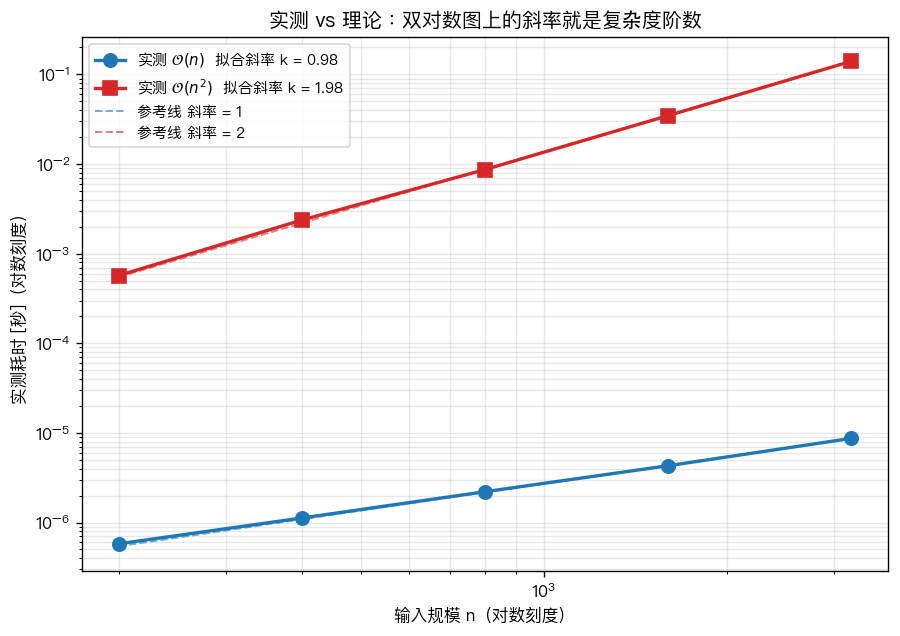

In [21]:
# 🧪 实验 8.2 —— 实测数据的双对数图：斜率一眼可见

if not HAS_MPL:
    print("没装 matplotlib，跳过画图（数据在上面的输出里）")
    print(f"（顺便报一下拟合结果：O(n) 的 k = {k_lin:.3f}，O(n^2) 的 k = {k_quad:.3f}）")
else:
    ns = [r[0] for r in rows]
    ts_lin = [r[1] for r in rows]
    ts_quad = [r[2] for r in rows]

    fig, ax = plt.subplots(figsize=(7.6, 5.4))

    # 实测数据
    ax.loglog(ns, ts_lin, "o-", lw=2, ms=8, color="#1f77b4",
              label=f"实测 $\\mathcal{{O}}(n)$  拟合斜率 k = {k_lin:.2f}")
    ax.loglog(ns, ts_quad, "s-", lw=2, ms=8, color="#d62728",
              label=f"实测 $\\mathcal{{O}}(n^2)$  拟合斜率 k = {k_quad:.2f}")

    # 参考直线：强制过最后一个实测点，斜率严格取 1 和 2
    ax.loglog(ns, [ts_lin[-1] * (n / ns[-1]) ** 1 for n in ns], "--", lw=1.2,
              color="#1f77b4", alpha=0.6, label="参考线 斜率 = 1")
    ax.loglog(ns, [ts_quad[-1] * (n / ns[-1]) ** 2 for n in ns], "--", lw=1.2,
              color="#d62728", alpha=0.6, label="参考线 斜率 = 2")

    ax.set_xlabel("输入规模 n（对数刻度）")
    ax.set_ylabel("实测耗时 [秒]（对数刻度）")
    ax.set_title("实测 vs 理论：双对数图上的斜率就是复杂度阶数")
    ax.grid(True, which="both", alpha=0.3)
    ax.legend(fontsize=9, loc="upper left")
    plt.tight_layout()
    plt.show()

**📖 这一格在做什么**

| 行 | 代码 | 人话 |
|---|---|---|
| 3-5 | `if not HAS_MPL:` | 没装 matplotlib 就打印拟合结果走人 —— **信息一点不丢**，只是没有图 |
| 7-9 | `ns / ts_lin / ts_quad` | 把上面表格里的三列拆成三个列表 |
| 11 | `plt.subplots(figsize=(7.6, 5.4))` | 一张 7.6×5.4 英寸的图 |
| 14-17 | `ax.loglog(ns, ts_lin, "o-", ...)` | `loglog` = **横纵轴都取对数**。`o-` 表示「圆点 + 实线」，`ms=8` 是点的大小 |
| 15 | `f"实测 $\\mathcal{{O}}(n)$ ..."` | **注意 f-string 里的大括号要写两遍** `{{}}` 才能输出一个字面大括号；而 `\\mathcal` 里的反斜杠在普通字符串里也要写两遍 |
| 20-23 | `ax.loglog(ns, [ts_lin[-1] * (n / ns[-1]) ** 1 ...])` | 画参考直线：**强制过最后一个实测点**，斜率严格取 1 和 2。公式是 $t = t_{\text{last}}\cdot(n/n_{\text{last}})^{k}$ |
| 25-26 | `set_xlabel / set_ylabel` | 坐标轴标签 —— **一定要标，而且要标清是「对数刻度」** |
| 29 | `ax.legend(fontsize=9, loc="upper left")` | 图例，放在左上角（那里空白最多） |

> 💡 **怎么读这张图**：
>
> - **蓝线（实测 $\mathcal{O}(n)$）** 应该几乎和**斜率 1 的虚线**重合；
> - **红线（实测 $\mathcal{O}(n^2)$）** 应该几乎和**斜率 2 的虚线**重合；
> - 如果哪条实测线**明显偏离**参考线（比如斜率测出来是 1.5），那说明三种可能：
>   ① n 还不够大，低阶项还在影响；② 测量被噪声污染了；③ **你以为的复杂度是错的**。
>
> 🎯 **这张图就是「实验验证复杂度」的标准做法** —— 物理里画 log-log 图定幂律，和这里**完全是同一件事**。

---

---
# §9 · 一张表收尾

## 复杂度速查表

| 记号 | 名字 | n 翻倍时工作量 | 一句话识别法 | 物理 / 数值例子 |
|---|---|---|---|---|
| $\mathcal{O}(1)$ | 常数 | 不变 | 没有循环，只有下标 / 哈希 | 取数组元素、查字典 |
| $\mathcal{O}(\log n)$ | 对数 | **+1 步** | 循环里 `n //= 2` 或区间对半砍 | 二分查找、二分法求根 |
| $\mathcal{O}(n)$ | 线性 | ×2 | 一层循环扫一遍 | 求和、找最大值、线性查找 |
| $\mathcal{O}(n\log n)$ | 线性对数 | ×2 多一点 | 分治 + 每层扫一遍 | 归并排序、Timsort、FFT |
| $\mathcal{O}(n^2)$ | 二次 | ×4 | 两层嵌套循环 | N 体问题、朴素矩阵乘法 |
| $\mathcal{O}(2^n)$ | 指数 | 平方级爆炸 | 每个元素「选 / 不选」 | 穷举子集、精确配分函数 |

## ⚠️ 三个最容易踩的坑

**坑 1：把 Big-O 当成「跑多快」。**
它是**形状**，不是**高度**。同一个 $\mathcal{O}(n\log n)$，C 写的 `sorted` 比手写 Python 快 100 倍（§7.2 实测）。
> **选算法看阶数，选实现看常数。**

**坑 2：忘了「平均 / 最坏」的区别。**
字典查询**平均** $\mathcal{O}(1)$、**最坏** $\mathcal{O}(n)$；快速排序**平均** $\mathcal{O}(n\log n)$、**最坏** $\mathcal{O}(n^2)$。
课件里那个 "on average" 不能丢。

**坑 3：只看循环层数就下结论。**
```python
# 看起来一层循环 —— 确实是 O(n)
for x in data:
    y = x * 2

# 看起来也是一层循环 —— 其实是 O(n^2)！
for x in data:
    j = data.index(x)      # 藏了一个 O(n) 在里面
```
**复杂度的乘法法则是「乘进循环体里面」去算的，不是数 `for` 的个数。**

## ✅ 三个该养成的好习惯

1. **先估阶，再写代码。**
   物理里的 n 常常是粒子数、格点数、时间步数。n = 10⁶ 时 $\mathcal{O}(n^2)$ 直接劝退 —— 该换算法了
   （邻居表、FFT、快速多极子、稀疏矩阵……）。
2. **计时永远测多次，取 `min()`。**
   标准写法：`min(timeit.repeat(...))`。§1.1 已经看到秒表会抖。
3. **画双对数图验阶。**
   斜率 = 阶数（§8 亲手量过）。这比「感觉变快了」可靠一万倍 —— 而且这本来就是物理人最熟的技能。

---

# §10 · 自测 6 题

> 先自己想，答案和验证代码在 §11。**不要直接往下翻。**

**题 1（辨认阶数）** 下面四段代码各是什么复杂度？用 n 表示。

```python
# (a)
total = 0
for x in data:          # data 的长度是 n
    total += x

# (b)
for i in range(n):
    for j in range(n):
        grid[i][j] = 0

# (c)
k = 0
while n > 1:
    n = n // 2
    k += 1

# (d)
for i in range(n):
    for j in range(i + 1, n):
        compute_force(i, j)
```

**题 2（数操作）** `for i in range(n): for j in range(n): count += 1`，当 n = 1000 时 `count` 是多少？用代码算出来验证。

**题 3（物理）** N 体问题：n = 100 个粒子需要算多少对相互作用力？
如果粒子数涨到 n = 1000（×10），计算量变成多少倍？再涨到 n = 10000 呢？

**题 4（对数）** 把二分查找用在 n = 10⁹（十亿）个元素的有序数组上，最坏要几步？
为什么说 $\mathcal{O}(\log n)$ 对「超大 n」依然便宜？

**题 5（交叉点）** 某 N 体模拟有两个实现：

- **实现 A**：朴素双重循环，$\mathcal{O}(n^2)$，但每次相互作用只要 **1 纳秒**（C 写的，很快）
- **实现 B**：用了邻居列表近似，$\mathcal{O}(n\log n)$，但每个粒子每步要 **100 纳秒**（Python 写的，很慢）

问：**n 多大时，B 开始比 A 快？** 用代码求解。

**题 6（坑）** 下面这段代码**看起来只有一层循环**，实际复杂度是多少？为什么？怎么改？

```python
def has_duplicates(data):
    for i in range(len(data)):
        if data[i] in data[i+1:]:
            return True
    return False
```

---

---
# §11 · 自测题答案与验证代码

## 题 1 答案

| 小题 | 复杂度 | 理由 |
|---|---|---|
| (a) | $\mathcal{O}(n)$ | 单层循环，n 次加法 |
| (b) | $\mathcal{O}(n^2)$ | 两层各自跑 n 次 ⇒ $n \times n$ |
| (c) | $\mathcal{O}(\log n)$ | 每步砍一半（`n //= 2`），砍 $\log_2 n$ 次到 1 |
| (d) | $\mathcal{O}(n^2)$ | 内层次数 $1+2+\dots+(n-1) = \frac{n(n-1)}{2}$，仍然是 $n^2$ 量级 |

> ⚠️ (d) 是最容易答错的一个：**「内层从 i+1 开始」只让次数减半，不改变阶数**。
> $\frac{1}{2}$ 是常数因子，Big-O 里丢掉。

## 题 2 答案：1,000,000

In [22]:
# 题 2 验证 —— n = 1000 的双层循环
n = 1000
count = 0
for i in range(n):
    for j in range(n):
        count += 1

print("实测 count =", f"{count:,}")
print("公式 n^2   =", f"{n ** 2:,}")
print("答案：两层各跑 n 次 ⇒ count = n^2 = 1,000,000")

实测 count = 1,000,000
公式 n^2   = 1,000,000
答案：两层各跑 n 次 ⇒ count = n^2 = 1,000,000


## 题 3 答案：约 4,950 对；×10 粒子 ⇒ ×100 计算量

In [23]:
# 题 3 验证 —— N 体问题的配对数
def pairs(n):
    """n 个粒子两两配对的数目 C(n,2)"""
    return n * (n - 1) // 2

print(f"{'粒子数 n':>10} | {'配对数 C(n,2)':>16} | {'约等于 n^2/2':>16} | {'相对上一行倍数':>16}")
print("-" * 70)
prev = None
for n in [100, 1_000, 10_000]:
    p = pairs(n)
    ratio = "--" if prev is None else f"{p / prev:>10.1f}x"
    print(f"{n:>10,} | {p:>16,} | {n * n // 2:>16,} | {ratio:>16}")
    prev = p

print()
print("n = 100   → 4,950 对")
print("n = 1000  → 499,500 对（粒子数 ×10，计算量 ×100）")
print("n = 10000 → 49,995,000 对（再 ×10，又 ×100）")
print()
print("这就是为什么分子动力学必须换算法：cell list / Verlet list / FMM / PM。")

     粒子数 n |       配对数 C(n,2) |        约等于 n^2/2 |          相对上一行倍数
----------------------------------------------------------------------
       100 |            4,950 |            5,000 |               --
     1,000 |          499,500 |          500,000 |           100.9x
    10,000 |       49,995,000 |       50,000,000 |           100.1x

n = 100   → 4,950 对
n = 1000  → 499,500 对（粒子数 ×10，计算量 ×100）
n = 10000 → 49,995,000 对（再 ×10，又 ×100）

这就是为什么分子动力学必须换算法：cell list / Verlet list / FMM / PM。


## 题 4 答案：最坏 30 步

In [24]:
# 题 4 验证 —— 十亿个元素要几步？
import math

n = 10 ** 9
print(f"n = {n:,}")
print(f"log2(n) = {math.log2(n):.3f}  →  向上取整 = {math.ceil(math.log2(n))} 步")
print()
print("对比一下：")
for k in [1, 2, 3, 6, 9, 12, 18]:
    big = 10 ** k
    print(f"  n = 10^{k:<3d} ({big:>21,}) → 二分只需要 {math.ceil(math.log2(big)):2d} 步")
print()
print("n 每乘 1000，步数只 +10。这就是「指数级的便宜」。")

n = 1,000,000,000
log2(n) = 29.897  →  向上取整 = 30 步

对比一下：
  n = 10^1   (                   10) → 二分只需要  4 步
  n = 10^2   (                  100) → 二分只需要  7 步
  n = 10^3   (                1,000) → 二分只需要 10 步
  n = 10^6   (            1,000,000) → 二分只需要 20 步
  n = 10^9   (        1,000,000,000) → 二分只需要 30 步
  n = 10^12  (    1,000,000,000,000) → 二分只需要 40 步
  n = 10^18  (1,000,000,000,000,000,000) → 二分只需要 60 步

n 每乘 1000，步数只 +10。这就是「指数级的便宜」。


## 题 5 答案：大约 n ≈ 1000

In [25]:
# 题 5 验证 —— 找 O(n^2) 小常数 vs O(n log n) 大常数的交叉点

COST_A = 1e-9      # 实现 A：每次相互作用 1 纳秒
COST_B = 100e-9    # 实现 B：每个粒子每步 100 纳秒

def time_A(n):
    return COST_A * n ** 2                 # O(n^2)

def time_B(n):
    return COST_B * n * math.log2(n)       # O(n log n)

crossover = None
for n in range(2, 200_001):
    if time_B(n) < time_A(n):
        crossover = n
        break

print(f"交叉点：n ≈ {crossover:,}")
print()
print(f"{'n':>8} | {'A: O(n^2), 1ns':>16} | {'B: O(n log n), 100ns':>22} | {'谁更快':>8}")
print("-" * 62)
for n in [10, 100, 500, crossover, 2_000, 10_000, 100_000]:
    ta, tb = time_A(n), time_B(n)
    who = "A" if ta < tb else "B"
    print(f"{n:>8,} | {ta * 1e3:>13.4f} ms | {tb * 1e3:>19.4f} ms | {who:>8}")

print()
print(f"结论：n < {crossover:,} 时，'笨但快'的 A 赢（常数小）；")
print(f"      n > {crossover:,} 时，'聪明但慢'的 B 赢（阶数低），而且越往后差距越大。")
print()
print("物理意义：小体系用最朴素的算法就行；大体系必须换阶数更低的算法。")

交叉点：n ≈ 997

       n |   A: O(n^2), 1ns |   B: O(n log n), 100ns |      谁更快
--------------------------------------------------------------
      10 |        0.0001 ms |              0.0033 ms |        A
     100 |        0.0100 ms |              0.0664 ms |        A
     500 |        0.2500 ms |              0.4483 ms |        A
     997 |        0.9940 ms |              0.9932 ms |        B
   2,000 |        4.0000 ms |              2.1932 ms |        B
  10,000 |      100.0000 ms |             13.2877 ms |        B
 100,000 |    10000.0000 ms |            166.0964 ms |        B

结论：n < 997 时，'笨但快'的 A 赢（常数小）；
      n > 997 时，'聪明但慢'的 B 赢（阶数低），而且越往后差距越大。

物理意义：小体系用最朴素的算法就行；大体系必须换阶数更低的算法。


## 题 6 答案：$\mathcal{O}(n^2)$

**为什么？** 拆开看那一行 `if data[i] in data[i+1:]:`，它其实干了**两件** $\mathcal{O}(n)$ 的事：

1. `data[i+1:]` —— **切片要复制**，复制 n−i−1 个元素 ⇒ $\mathcal{O}(n)$；
2. `... in ...` —— 在切片里**逐个比对** ⇒ $\mathcal{O}(n)$。

这两个 $\mathcal{O}(n)$ 都在外层循环里，外层跑 n 次 ⇒ 总复杂度 $\mathcal{O}(n^2)$。

> 💡 **附带一提**：这段代码还有个内存问题 —— 每次循环都**新建一个切片**，峰值额外内存 $\mathcal{O}(n)$。
> 而且它在**找到第一对重复就返回**，所以：
> - **最好情况**（前两个就重复）$\mathcal{O}(n)$ —— 光造切片就花了 $\mathcal{O}(n)$；
> - **最坏情况**（完全没有重复，比如全不相同的数）$\mathcal{O}(n^2)$。

**怎么改？** 用集合（哈希表）记录见过的元素 —— 集合的 `in` 是平均 $\mathcal{O}(1)$：

In [26]:
# 题 6 验证 —— 慢版本 vs 集合版本

def has_duplicates_slow(data):
    """题目里那段：看起来一层循环，其实 O(n^2)。"""
    for i in range(len(data)):
        if data[i] in data[i+1:]:      # 切片 O(n) + 查找 O(n)
            return True
    return False

def has_duplicates_fast(data):
    """集合版：把「见过谁」记在哈希表里，平均 O(n)。"""
    seen = set()
    for x in data:
        if x in seen:                  # 集合查找：平均 O(1)
            return True
        seen.add(x)
    return False

# 先确认两个函数行为一致
test_cases = [[1, 2, 3, 4], [1, 2, 3, 2], [], [7, 7], list(range(50))]
for tc in test_cases:
    assert has_duplicates_slow(tc) == has_duplicates_fast(tc), f"结果不一致: {tc}"
print("两个函数在", len(test_cases), "组测试数据上结果一致 ✓")
print()

# 最坏情况：完全没有重复
print(f"{'n':>8} | {'慢版本 O(n^2) [ms]':>20} | {'集合版 O(n) [ms]':>18} | {'慢了几倍':>10}")
print("-" * 66)
for n in [500, 1_000, 2_000, 4_000]:
    data = list(range(n))             # 全不相同 = 最坏情况，要扫完
    t0 = time.perf_counter(); has_duplicates_slow(data); t_slow = time.perf_counter() - t0
    t0 = time.perf_counter(); has_duplicates_fast(data); t_fast = time.perf_counter() - t0
    print(f"{n:>8,} | {t_slow * 1000:>20.3f} | {t_fast * 1000:>18.4f} | {t_slow / t_fast:>10.1f}x")

print()
print("注意最后一列在随 n 变大 —— 因为一个是 O(n^2)，一个是 O(n)，")
print("它们的比值本身就在按 n 增长。这才是「阶数不同」的铁证。")

两个函数在 5 组测试数据上结果一致 ✓

       n |      慢版本 O(n^2) [ms] |      集合版 O(n) [ms] |       慢了几倍
------------------------------------------------------------------
     500 |                0.572 |             0.0122 |       47.0x
   1,000 |                2.190 |             0.0220 |       99.7x
   2,000 |                8.644 |             0.0518 |      166.8x
   4,000 |               36.287 |             0.0858 |      423.0x

注意最后一列在随 n 变大 —— 因为一个是 O(n^2)，一个是 O(n)，
它们的比值本身就在按 n 增长。这才是「阶数不同」的铁证。


---
# 结语

回到课件开头那句话：

> Measuring how "fast" a program runs by using a stopwatch in seconds isn't really useful...

这份 notebook 从头到尾都在贯彻它。把这一章压缩成三句话：

1. **复杂度量的是曲线的形状，不是高度。** —— 所以用「操作次数」而不是秒表。
2. **形状由「n 翻倍时工作量怎么变」决定。** —— ×1 是常数、+1 是对数、×2 是线性、×4 是二次。
3. **验证形状的标准工具是双对数图的斜率。** —— 物理人本来就会这一招。

## 这张表建议直接背下来

| 看到什么 | 想到什么 |
|---|---|
| 按下标取值、哈希查询 | $\mathcal{O}(1)$ |
| `while n > 1: n //= 2`、区间对半砍 | $\mathcal{O}(\log n)$ |
| 一层循环扫全部 | $\mathcal{O}(n)$ |
| 分治 + 每层扫一遍 | $\mathcal{O}(n\log n)$ |
| 两层嵌套、两两配对 | $\mathcal{O}(n^2)$ |
| 每个元素「选 / 不选」 | $\mathcal{O}(2^n)$ |

## 下一步可以自己做的事

- 把 §8 的网格扩到 n = 10⁵，看看 $\mathcal{O}(n\log n)$ 的曲线怎么从 $\mathcal{O}(n)$ 旁边「微微翘起来」；
- 给 §5 的 N 体问题加一个 **cell list**，实测它把 $\mathcal{O}(n^2)$ 压到接近 $\mathcal{O}(n)$ 的效果；
- 用 `matplotlib` 把 §6 的「二分步数 vs n」画出来，和 $y=\log_2 n$ 叠在一起；
- 拿 Python 的 `timeit` 测一下你自己写的物理代码，找出里面藏着的 $\mathcal{O}(n^2)$。

> 🎓 **Tutorial 4 完。** 下一章如果讲文件读写或绘图，这份 notebook 里所有的计时 / 验证套路都可以直接搬过去用。